## General Libraries Needed

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


# Example 1: Comparing Sample Preparation Methods

## 1A) Similarity Index

### Heat map of Similarity Index for Comparing Methods.

In [2]:
# File path for figure
file_SI_matrix = './M03_raw_data_for_figures/methods_top_100_similarity_dataframe.csv'

# Import Similarity Dataframe
similarity_matrix = pd.read_csv(file_SI_matrix)
similarity_matrix

,sample,EZpep_Sonic_N1,EZpep_Sonic_N2,EZpep_Sonic_N3,EZpep_Sonic_N4,EZpep_Sonic_N5,SDC_Amide_Sonic_N1,SDC_Amide_Sonic_N2,SDC_Amide_Sonic_N3,SDC_Amide_Sonic_N4,...,Strap_Sonic_N1,Strap_Sonic_N2,Strap_Sonic_N3,Strap_Sonic_N4,Strap_Sonic_N5,Urea_Sonic_N1,Urea_Sonic_N2,Urea_Sonic_N3,Urea_Sonic_N4,Urea_Sonic_N5
0,EZpep_Sonic_N1,1.000000,0.730798,0.725125,0.713254,0.694456,0.461375,0.425297,0.449770,0.469209,...,0.424818,0.510710,0.466054,0.484544,0.486248,0.528554,0.513929,0.502789,0.504782,0.421332
1,EZpep_Sonic_N2,0.730798,1.000000,0.791212,0.760935,0.733858,0.469495,0.439225,0.448599,0.460654,...,0.460421,0.517630,0.482182,0.492289,0.499174,0.552329,0.542494,0.527492,0.535650,0.433920
2,EZpep_Sonic_N3,0.725125,0.791212,1.000000,0.792294,0.729987,0.462258,0.447144,0.456533,0.457609,...,0.470627,0.540972,0.498147,0.497011,0.515167,0.533258,0.533036,0.510801,0.517833,0.423133
3,EZpep_Sonic_N4,0.713254,0.760935,0.792294,1.000000,0.742023,0.470977,0.447525,0.453571,0.460398,...,0.446683,0.527448,0.484139,0.501203,0.508165,0.552484,0.540857,0.522446,0.528779,0.437203
4,EZpep_Sonic_N5,0.694456,0.733858,0.729987,0.742023,1.000000,0.477396,0.443591,0.452758,0.472798,...,0.450795,0.514717,0.469570,0.504741,0.520567,0.535813,0.530081,0.511988,0.512969,0.432809
5,SDC_Amide_Sonic_N1,0.461375,0.469495,0.462258,0.470977,0.477396,1.000000,0.731227,0.712261,0.720837,...,0.446369,0.470824,0.428973,0.416301,0.457933,0.463372,0.451782,0.438924,0.444177,0.500922
6,SDC_Amide_Sonic_N2,0.425297,0.439225,0.447144,0.447525,0.443591,0.731227,1.000000,0.668250,0.680592,...,0.431239,0.453203,0.405786,0.401499,0.445505,0.438253,0.442253,0.428630,0.430805,0.467928
7,SDC_Amide_Sonic_N3,0.449770,0.448599,0.456533,0.453571,0.452758,0.712261,0.668250,1.000000,0.704160,...,0.456483,0.486911,0.448058,0.453585,0.473175,0.449482,0.435361,0.425299,0.436531,0.488346
8,SDC_Amide_Sonic_N4,0.469209,0.460654,0.457609,0.460398,0.472798,0.720837,0.680592,0.704160,1.000000,...,0.468071,0.497666,0.444890,0.438188,0.482008,0.458583,0.457765,0.432011,0.445700,0.500698
9,SDC_Amide_Sonic_N5,0.454312,0.471243,0.458011,0.451684,0.465202,0.665678,0.650443,0.681226,0.702042,...,0.449571,0.481843,0.429758,0.440552,0.461437,0.439196,0.434816,0.417360,0.426650,0.471241


In [3]:
# Data Wrangling

# Remove the string "_sonic" sonic from all the column names
similarity_matrix.columns = similarity_matrix.columns.str.replace('_Sonic', '', regex=False)
# Strip any leading/trailing spaces that might remain.  (There shouldn't be any.)
similarity_matrix.columns = similarity_matrix.columns.str.strip()

# Remove Sonic from all the sample names
similarity_matrix['sample'] = similarity_matrix['sample'].str.replace('_Sonic', '', case=False, regex=False)

# Make the sample column the index
similarity_matrix = similarity_matrix.set_index('sample')

# Replace elements below the main diagonal with NaN
similarity_matrix = similarity_matrix.where(np.triu(np.ones(similarity_matrix.shape, dtype=bool)))


# Reverse order of all columns
# similarity_matrix = similarity_matrix.iloc[:, ::-1]

similarity_matrix

,EZpep_N1,EZpep_N2,EZpep_N3,EZpep_N4,EZpep_N5,SDC_Amide_N1,SDC_Amide_N2,SDC_Amide_N3,SDC_Amide_N4,SDC_Amide_N5,...,Strap_N1,Strap_N2,Strap_N3,Strap_N4,Strap_N5,Urea_N1,Urea_N2,Urea_N3,Urea_N4,Urea_N5
sample,,,,,,,,,,,,,,,,,,,,,
EZpep_N1,1.0,0.730798,0.725125,0.713254,0.694456,0.461375,0.425297,0.449770,0.469209,0.454312,...,0.424818,0.510710,0.466054,0.484544,0.486248,0.528554,0.513929,0.502789,0.504782,0.421332
EZpep_N2,NaN,1.000000,0.791212,0.760935,0.733858,0.469495,0.439225,0.448599,0.460654,0.471243,...,0.460421,0.517630,0.482182,0.492289,0.499174,0.552329,0.542494,0.527492,0.535650,0.433920
EZpep_N3,NaN,NaN,1.000000,0.792294,0.729987,0.462258,0.447144,0.456533,0.457609,0.458011,...,0.470627,0.540972,0.498147,0.497011,0.515167,0.533258,0.533036,0.510801,0.517833,0.423133
EZpep_N4,NaN,NaN,NaN,1.000000,0.742023,0.470977,0.447525,0.453571,0.460398,0.451684,...,0.446683,0.527448,0.484139,0.501203,0.508165,0.552484,0.540857,0.522446,0.528779,0.437203
EZpep_N5,NaN,NaN,NaN,NaN,1.000000,0.477396,0.443591,0.452758,0.472798,0.465202,...,0.450795,0.514717,0.469570,0.504741,0.520567,0.535813,0.530081,0.511988,0.512969,0.432809
SDC_Amide_N1,NaN,NaN,NaN,NaN,NaN,1.000000,0.731227,0.712261,0.720837,0.665678,...,0.446369,0.470824,0.428973,0.416301,0.457933,0.463372,0.451782,0.438924,0.444177,0.500922
SDC_Amide_N2,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.668250,0.680592,0.650443,...,0.431239,0.453203,0.405786,0.401499,0.445505,0.438253,0.442253,0.428630,0.430805,0.467928
SDC_Amide_N3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.704160,0.681226,...,0.456483,0.486911,0.448058,0.453585,0.473175,0.449482,0.435361,0.425299,0.436531,0.488346
SDC_Amide_N4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.702042,...,0.468071,0.497666,0.444890,0.438188,0.482008,0.458583,0.457765,0.432011,0.445700,0.500698


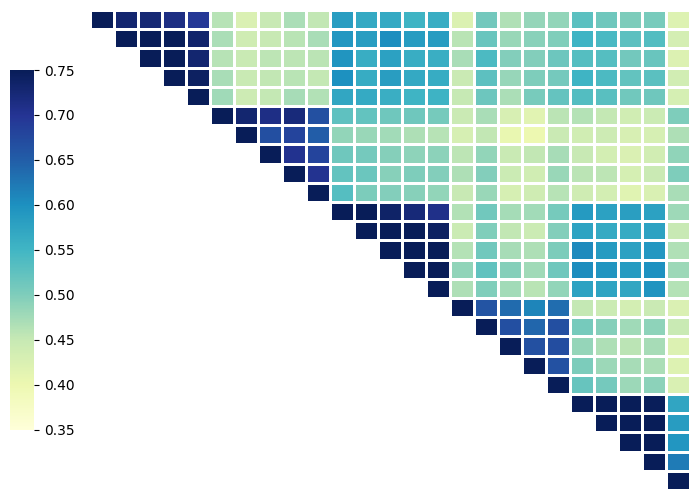

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

fig = plt.figure(figsize=(8, 6))

# Create axes: [left, bottom, width, height]
cbar_ax = fig.add_axes([0.05, 0.2, 0.03, 0.6])   # left side colorbar
ax = fig.add_axes([0.15, 0.1, 0.75, 0.8])        # main heatmap

sns.heatmap(
    similarity_matrix,
    cmap="YlGnBu",
    vmin=0.35,
    vmax=0.75, 
    linewidths=1.0,
    cbar=True,
    cbar_ax=cbar_ax,
    ax=ax
)

# Remove labels on both Axis
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")


# Saves the image as a .jpg file
plt.savefig('Heatmap_of_Methods_Study.jpg')

plt.show()


In [5]:
# The figure was than imported into PowerPoint and annotated manually

## 1B) PSMs, Peptides, and Proteins for Example 1: Importing Data

In [6]:
# File path for figure
file_PSM_by_run = './M03_raw_data_for_figures/methods_top_100_summary_info.csv'
file_PSM_by_group = './M03_raw_data_for_figures/methods_top_100_summary_stats.csv'

# Import Similarity Dataframe
PSM_by_run = pd.read_csv(file_PSM_by_run)
PSM_by_group = pd.read_csv(file_PSM_by_group)
PSM_by_run

,Unnamed: 0,EZpep_Sonic_N1,EZpep_Sonic_N2,EZpep_Sonic_N3,EZpep_Sonic_N4,EZpep_Sonic_N5,SDC_Amide_Sonic_N1,SDC_Amide_Sonic_N2,SDC_Amide_Sonic_N3,SDC_Amide_Sonic_N4,...,Strap_Sonic_N1,Strap_Sonic_N2,Strap_Sonic_N3,Strap_Sonic_N4,Strap_Sonic_N5,Urea_Sonic_N1,Urea_Sonic_N2,Urea_Sonic_N3,Urea_Sonic_N4,Urea_Sonic_N5
0,Protein Groups,5417,5536,5371,5364,5400,5980,6057,5972,6079,...,3946,4205,4289,4225,4133,5332,5283,5155,5170,5069
1,Peptides,30877,30773,29688,30462,30094,33741,32783,33807,33789,...,17534,19925,19703,18731,19057,33624,33256,31999,32123,32128
2,PSM,36667,36944,35441,36481,36063,39333,38213,39615,39268,...,20084,22942,22486,21372,22041,41490,41350,40264,40256,39329


### Spectral Count Per Run Figures for First Example (Comparing Methods).

In [7]:
PSM_by_run = PSM_by_run.set_index('Unnamed: 0')

# transpose PSM DataFrame
PSM_by_run_T = PSM_by_run.T


PSM_by_run_T = PSM_by_run_T.reset_index()
PSM_by_run_T[['method', 'sample']] = PSM_by_run_T['index'].str.split('_Sonic', expand=True, n=2)
PSM_by_run_T

Unnamed: 0,index,Protein Groups,Peptides,PSM,method,sample
0,EZpep_Sonic_N1,5417,30877,36667,EZpep,_N1
1,EZpep_Sonic_N2,5536,30773,36944,EZpep,_N2
2,EZpep_Sonic_N3,5371,29688,35441,EZpep,_N3
3,EZpep_Sonic_N4,5364,30462,36481,EZpep,_N4
4,EZpep_Sonic_N5,5400,30094,36063,EZpep,_N5
5,SDC_Amide_Sonic_N1,5980,33741,39333,SDC_Amide,_N1
6,SDC_Amide_Sonic_N2,6057,32783,38213,SDC_Amide,_N2
7,SDC_Amide_Sonic_N3,5972,33807,39615,SDC_Amide,_N3
8,SDC_Amide_Sonic_N4,6079,33789,39268,SDC_Amide,_N4
9,SDC_Amide_Sonic_N5,5933,31568,36893,SDC_Amide,_N5


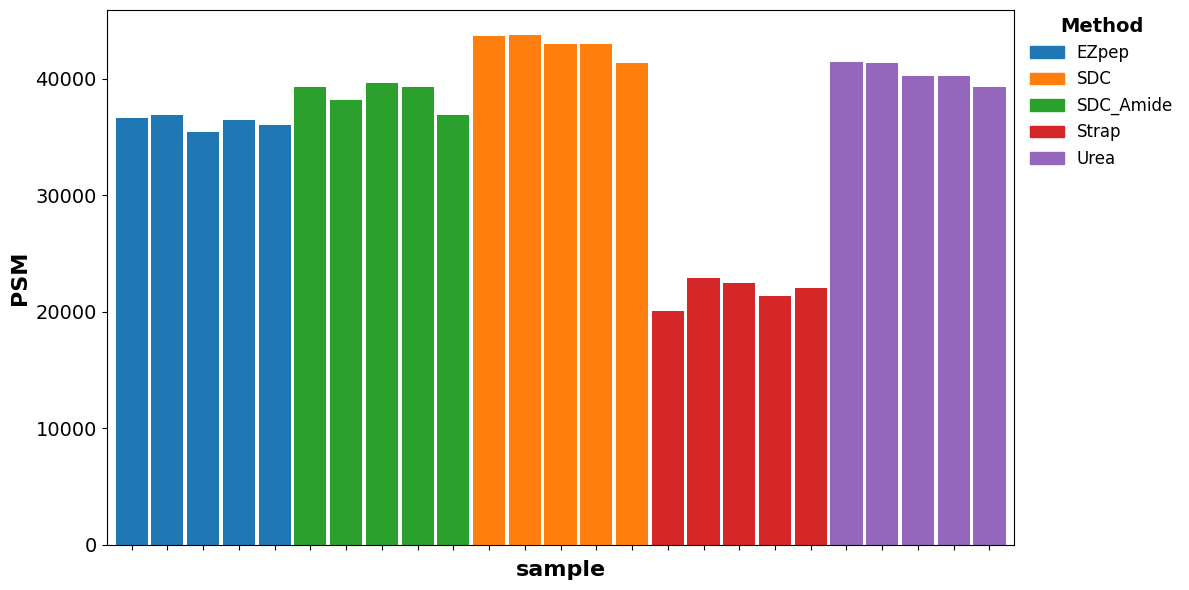

In [8]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


# Convert 'method' column to categorical and assign colors
categories = PSM_by_run_T['method'].astype('category')
cmap = plt.get_cmap('tab10')
category_to_color = {cat: cmap(code) for code, cat in enumerate(categories.cat.categories)}


# Create bar plot
ax = PSM_by_run_T.plot(
    kind='bar',
    x='index',
    y='PSM',
    color=[category_to_color[m] for m in PSM_by_run_T['method']],
    width=0.9,
    legend=False,
    figsize=(12, 6)
)

# Remove x-tick labels
ax.set_xticklabels([])

# Set axis labels with larger, bold font
ax.set_xlabel("sample", fontsize=16, fontweight='bold')
ax.set_ylabel("PSM", fontsize=16, fontweight='bold')

# Enlarge tick labels
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)

# Create legend handles
handles = [mpatches.Patch(color=color, label=cat) for cat, color in category_to_color.items()]

# Add legend outside on the right
legend = ax.legend(
    handles=handles,
    title="Method",
    fontsize=12,
    loc='upper left',
    bbox_to_anchor=(1.01, 1),
    borderaxespad=0,
    frameon=False
)

# Make legend title bold and larger
legend.get_title().set_fontsize(14)
legend.get_title().set_fontweight('bold')

plt.tight_layout()



# Saves the image as a .jpg file
plt.savefig('PSMs_for_first_Example_C.jpg')
plt.show()


### Peptides per Run Figures for First Example (Comparing Methods).

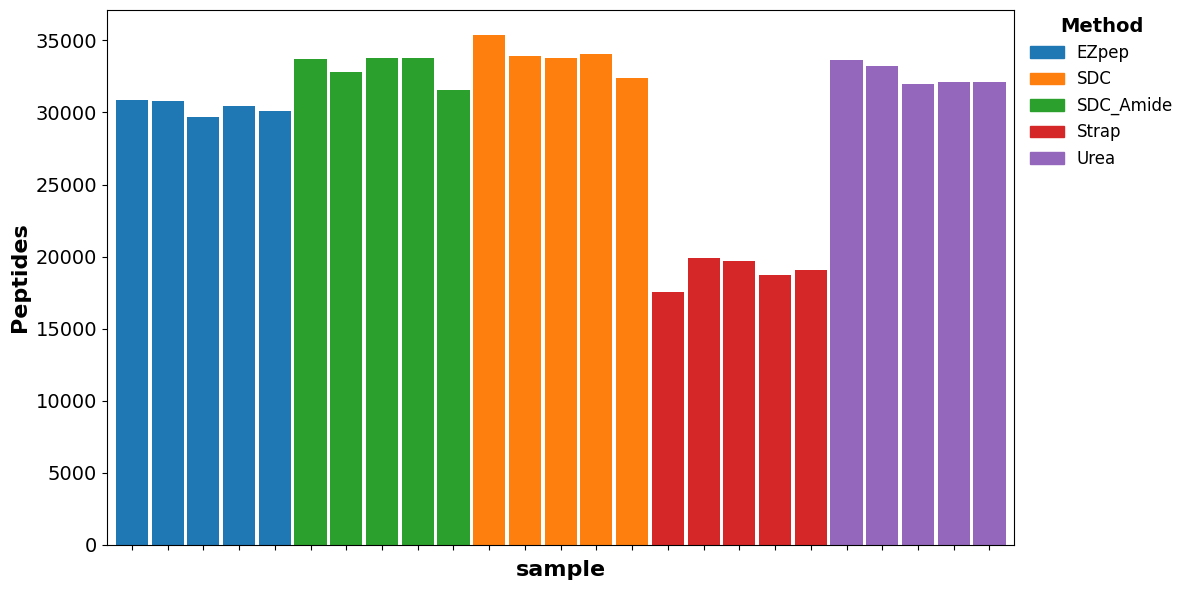

In [9]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


# Convert 'method' column to categorical and assign colors
categories = PSM_by_run_T['method'].astype('category')
cmap = plt.get_cmap('tab10')
category_to_color = {cat: cmap(code) for code, cat in enumerate(categories.cat.categories)}


# Create bar plot
ax = PSM_by_run_T.plot(
    kind='bar',
    x='index',
    y='Peptides',
    color=[category_to_color[m] for m in PSM_by_run_T['method']],
    width=0.9,
    legend=False,
    figsize=(12, 6)
)

# Remove x-tick labels
ax.set_xticklabels([])

# Set axis labels with larger, bold font
ax.set_xlabel("sample", fontsize=16, fontweight='bold')
ax.set_ylabel("Peptides", fontsize=16, fontweight='bold')

# Enlarge tick labels
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)

# Create legend handles
handles = [mpatches.Patch(color=color, label=cat) for cat, color in category_to_color.items()]

# Add legend outside on the right
legend = ax.legend(
    handles=handles,
    title="Method",
    fontsize=12,
    loc='upper left',
    bbox_to_anchor=(1.01, 1),
    borderaxespad=0,
    frameon=False
)

# Make legend title bold and larger
legend.get_title().set_fontsize(14)
legend.get_title().set_fontweight('bold')

plt.tight_layout()



# Saves the image as a .jpg file
plt.savefig('PSMs_for_first_Example_C.jpg')
plt.show()


### Proteins per Run Figures for First Example (Comparing Methods).

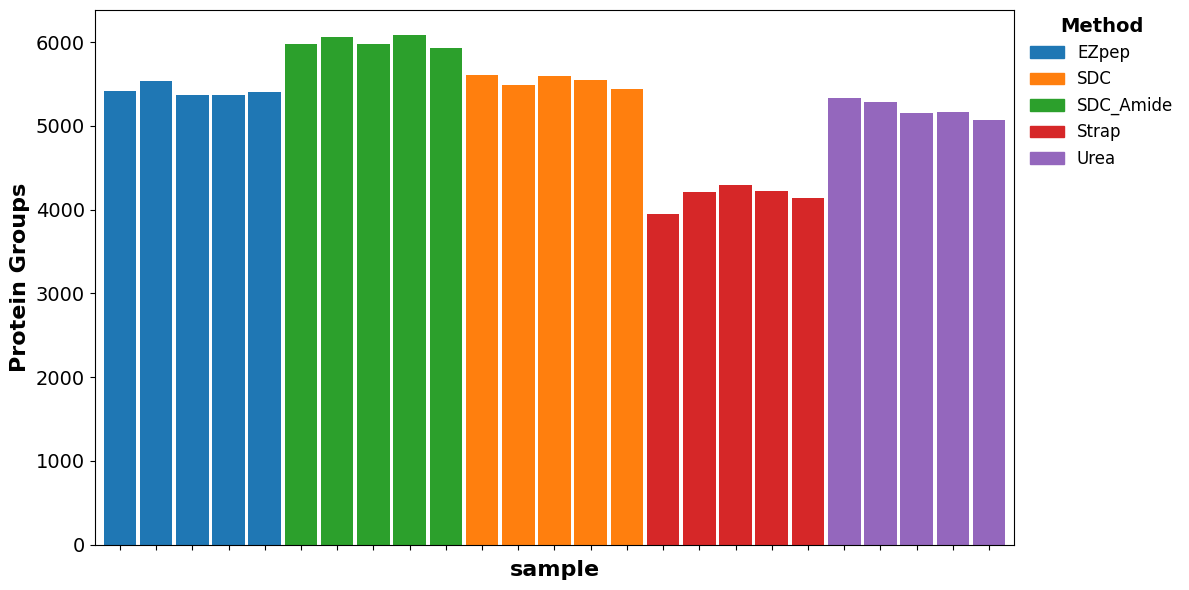

In [10]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Convert 'method' column to categorical and assign colors
categories = PSM_by_run_T['method'].astype('category')
cmap = plt.get_cmap('tab10')
category_to_color = {cat: cmap(code) for code, cat in enumerate(categories.cat.categories)}

# Create bar plot
ax = PSM_by_run_T.plot(
    kind='bar',
    x='index',
    y='Protein Groups',
    color=[category_to_color[m] for m in PSM_by_run_T['method']],
    width=0.9,
    legend=False,
    figsize=(12, 6)
)

# Remove x-tick labels
ax.set_xticklabels([])

# Set axis labels with larger, bold font
ax.set_xlabel("sample", fontsize=16, fontweight='bold')
ax.set_ylabel("Protein Groups", fontsize=16, fontweight='bold')

# Enlarge tick labels
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)

# Create legend handles
handles = [mpatches.Patch(color=color, label=cat) for cat, color in category_to_color.items()]

# Add legend outside on the right
legend = ax.legend(
    handles=handles,
    title="Method",
    fontsize=12,
    loc='upper left',
    bbox_to_anchor=(1.01, 1),
    borderaxespad=0,
    frameon=False
)

# Make legend title bold and larger
legend.get_title().set_fontsize(14)
legend.get_title().set_fontweight('bold')

plt.tight_layout()




# Saves the image as a .jpg file
plt.savefig('Protein_Groups_for_first_Example_B.jpg')
plt.show()


### Spectral Count Per Group Figure

In [11]:
PSM_by_group

,Unnamed: 0,property,group,mean,sd,p_value_vs_A
0,0,Protein Groups,A,5417.6,69.593822,1.000000e+00
1,1,Protein Groups,B,6004.2,61.389739,6.103950e-07
2,2,Protein Groups,C,5535.6,70.532262,2.867665e-02
3,3,Protein Groups,D,4159.6,131.733823,6.402840e-08
4,4,Protein Groups,E,5201.8,105.336129,5.074308e-03
5,5,Peptides,A,30378.8,492.147031,1.000000e+00
6,6,Peptides,B,33137.6,977.994785,4.901793e-04
7,7,Peptides,C,33894.6,1056.821319,1.460211e-04
8,8,Peptides,D,18990.0,945.264513,1.001995e-08
9,9,Peptides,E,32626.0,756.149126,5.287049e-04


In [12]:
PSM_df = PSM_by_group[PSM_by_group['property'] == 'PSM'].copy()
PSM_df['method'] = ['EZpep', 'SDC', 'SDC_Amide', 'Strap', 'Urea']
PSM_df

,Unnamed: 0,property,group,mean,sd,p_value_vs_A,method
10,10,PSM,A,36319.2,586.172500,1.000000e+00,EZpep
11,11,PSM,B,38664.4,1124.346388,3.272417e-03,SDC
12,12,PSM,C,42964.0,974.762535,1.120051e-06,SDC_Amide
13,13,PSM,D,21785.0,1113.503031,5.420324e-09,Strap
14,14,PSM,E,40537.8,891.898088,2.116654e-05,Urea


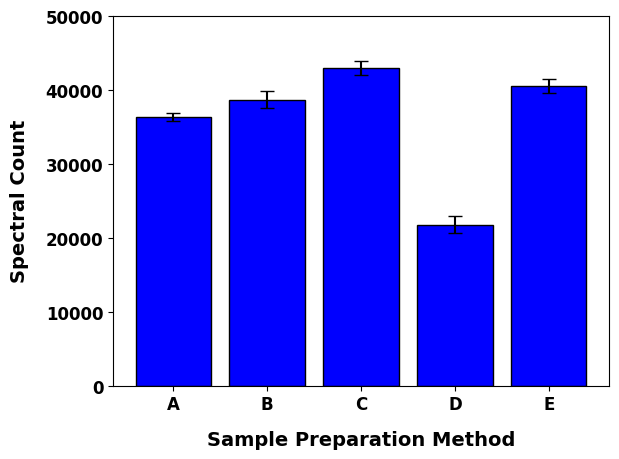

In [13]:


# Create the bar chart
plt.bar(PSM_df['group'], PSM_df['mean'], yerr=PSM_df['sd'], capsize=5, color='blue', edgecolor='black')

# Add labels and title
plt.xlabel('Sample Preparation Method', fontsize=14, fontweight='bold', labelpad=12)
plt.ylabel('Spectral Count', fontsize=14, fontweight='bold', labelpad=12)

plt.ylim(0, 50000)

# Make tick labels bold
plt.xticks(fontsize=12, fontweight='bold')
plt.yticks(fontsize=12, fontweight='bold')

# Saves the image as a .jpg file
plt.savefig('PSMs_per_group_first_Example.jpg')

# Save the Figure as a jpg file
plt.savefig('PSMs_per_group_Example_1A.jpg', dpi=300, bbox_inches='tight')


# Display the plot
plt.show()


### Peptides Per Group Figure for Example 1

In [14]:
peptides_df = PSM_by_group[PSM_by_group['property'] == 'Peptides'].copy()
peptides_df['method'] = ['EZpep', 'SDC', 'SDC_Amide', 'Strap', 'Urea']
peptides_df

,Unnamed: 0,property,group,mean,sd,p_value_vs_A,method
5,5,Peptides,A,30378.8,492.147031,1.000000e+00,EZpep
6,6,Peptides,B,33137.6,977.994785,4.901793e-04,SDC
7,7,Peptides,C,33894.6,1056.821319,1.460211e-04,SDC_Amide
8,8,Peptides,D,18990.0,945.264513,1.001995e-08,Strap
9,9,Peptides,E,32626.0,756.149126,5.287049e-04,Urea


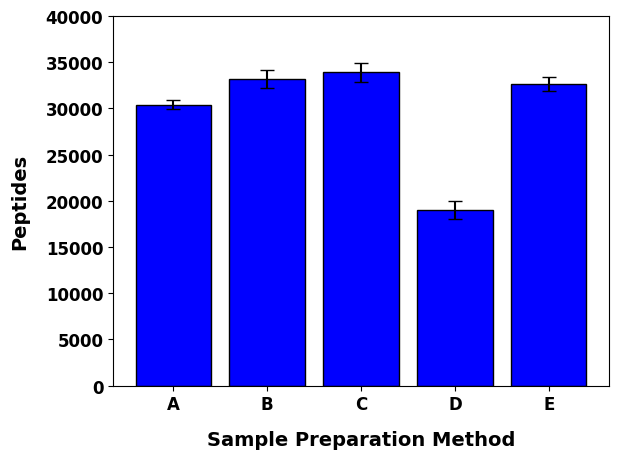

In [15]:


# Create the bar chart
plt.bar(peptides_df['group'], peptides_df['mean'], yerr=peptides_df['sd'], capsize=5, color='blue', edgecolor='black')

plt.ylim(0, 40000)
# Add labels and title
plt.xlabel('Sample Preparation Method', fontsize=14, fontweight='bold', labelpad=12)
plt.ylabel('Peptides', fontsize=14, fontweight='bold', labelpad=12)

# Make tick labels bold
plt.xticks(fontsize=12, fontweight='bold')
plt.yticks(fontsize=12, fontweight='bold')


# Save the Figure as a jpg file
plt.savefig('Peptides_per_group_Example_1A.jpg', dpi=300, bbox_inches='tight')


# Display the plot
plt.show()


### Protein Groups Per Group Figure for Example 1

In [16]:
proteins_df = PSM_by_group[PSM_by_group['property'] == 'Protein Groups'].copy()
proteins_df['method'] = ['EZpep', 'SDC', 'SDC_Amide', 'Strap', 'Urea']
proteins_df

,Unnamed: 0,property,group,mean,sd,p_value_vs_A,method
0,0,Protein Groups,A,5417.6,69.593822,1.000000e+00,EZpep
1,1,Protein Groups,B,6004.2,61.389739,6.103950e-07,SDC
2,2,Protein Groups,C,5535.6,70.532262,2.867665e-02,SDC_Amide
3,3,Protein Groups,D,4159.6,131.733823,6.402840e-08,Strap
4,4,Protein Groups,E,5201.8,105.336129,5.074308e-03,Urea


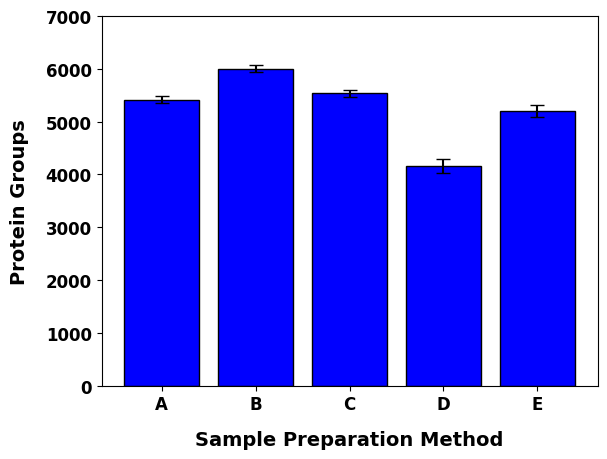

In [17]:


# Create the bar chart
plt.bar(proteins_df['group'], proteins_df['mean'], yerr=proteins_df['sd'], capsize=5, color='blue', edgecolor='black')

# Add labels and title
plt.xlabel('Sample Preparation Method', fontsize=14, fontweight='bold', labelpad=12)
plt.ylabel('Protein Groups', fontsize=14, fontweight='bold', labelpad=12)

plt.ylim(0, 7000)
# Make tick labels bold
plt.xticks(fontsize=12, fontweight='bold')
plt.yticks(fontsize=12, fontweight='bold')


# Saves the image as a .jpg file

plt.savefig('Proteins_per_group_Example_1A.jpg', dpi=300, bbox_inches='tight')

# Display the plot
plt.show()


## 1C) Bar Chart for peptide Length

In [18]:
# File path for figure
peptide_length_stats_path = './M03_raw_data_for_figures/methods_top_100_peptide_length_stats_df.csv'

# Import Peptide Length Dataframe
peptide_length_stats_df = pd.read_csv(peptide_length_stats_path)
peptide_length_stats_df

,Unnamed: 0,group,pept_len,mean,std
0,0,A,6,47.2,1.788854
1,1,A,7,108.6,5.683309
2,2,A,8,176.2,14.078352
3,3,A,9,210.2,15.368800
4,4,A,10,205.2,11.519549
...,...,...,...,...,...
70,70,E,16,295.2,19.954949
71,71,E,17,190.0,12.845233
72,72,E,18,161.4,18.201648
73,73,E,19,158.0,5.830952


In [19]:
def normalized_per_group(peptide_length_stats_df):
    unique_groups = peptide_length_stats_df['group'].unique()
    modified_df = pd.DataFrame()

    for group_i in unique_groups:
        group_i_df = peptide_length_stats_df[
            peptide_length_stats_df['group'] == group_i
        ].copy()

        total_pept_counts_i = group_i_df['mean'].sum()

        group_i_df['normalized_mean'] = group_i_df['mean'] / total_pept_counts_i
        group_i_df['normalized_std'] = group_i_df['std'] / total_pept_counts_i

        modified_df = pd.concat([modified_df, group_i_df], ignore_index=True)
    modified_df = modified_df.drop(['mean', 'std'], axis = 1)
    modified_df = modified_df.rename(columns={'normalized_mean': 'mean', 'normalized_std': 'std'})

    return modified_df

norm_peptide_length_df = normalized_per_group(peptide_length_stats_df)
norm_peptide_length_df

,Unnamed: 0,group,pept_len,mean,std
0,0,A,6,0.021350,0.000809
1,1,A,7,0.049122,0.002571
2,2,A,8,0.079700,0.006368
3,3,A,9,0.095079,0.006952
4,4,A,10,0.092817,0.005211
...,...,...,...,...,...
70,70,E,16,0.099770,0.006744
71,71,E,17,0.064215,0.004341
72,72,E,18,0.054549,0.006152
73,73,E,19,0.053400,0.001971


In [20]:


def plot_peptide_length_by_group(peptide_length_stats_df):
    fig, ax = plt.subplots(figsize=(8, 5))

    # Get unique groups and peptide lengths
    groups = peptide_length_stats_df["group"].unique()
    pept_lens = peptide_length_stats_df["pept_len"].unique()

    # Draw barplot WITHOUT seaborn error bars
    sns.barplot(
        data=peptide_length_stats_df,
        x="pept_len",
        y="mean",
        hue="group",
        errorbar=None,
        ax=ax
    )

    # --- Add SD error bars manually ---
    n_groups = len(groups)
    bar_width = 0.8 / n_groups  # seaborn default total width ≈ 0.8

    for i, group in enumerate(groups):
        group_df = peptide_length_stats_df[peptide_length_stats_df["group"] == group]

        x_positions = (
            np.arange(len(pept_lens))
            - 0.4
            + bar_width / 2
            + i * bar_width
        )

        ax.errorbar(
            x=x_positions,
            y=group_df["mean"],
            yerr=group_df["std"],
            fmt="none",
            ecolor="black",
            capsize=1.5,
            linewidth=0.5
        )

    ax.set_xlabel("Peptide Length")
    ax.set_ylabel("Number of Peptides (normalized)")
    plt.savefig('Methods_Pept_length_by_group.jpg', dpi=300, bbox_inches='tight')

    fig.tight_layout()
    return fig






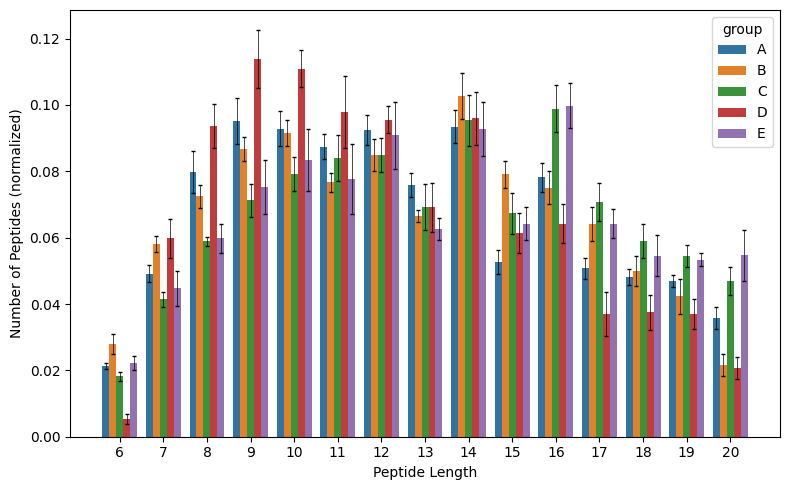

In [21]:
norm_pept_len_plot = plot_peptide_length_by_group(norm_peptide_length_df)


## 1D) Gravy Scores example

In [22]:
# File path for figure
gravy_path = './M03_raw_data_for_figures/methods_top_100_AA_index_008_var.csv'

# Import Hydrophobicity Dataframe
gravy_df = pd.read_csv(gravy_path)
gravy_df = gravy_df[['property_X', 'group']]
gravy_df = gravy_df.rename(columns={'property_X': 'gravy score'})
gravy_df

,gravy score,group
0,43.011111,A
1,55.946154,A
2,59.307143,A
3,47.407692,A
4,45.045455,A
...,...,...
58578,44.541667,E
58579,44.541667,E
58580,46.650000,E
58581,46.650000,E


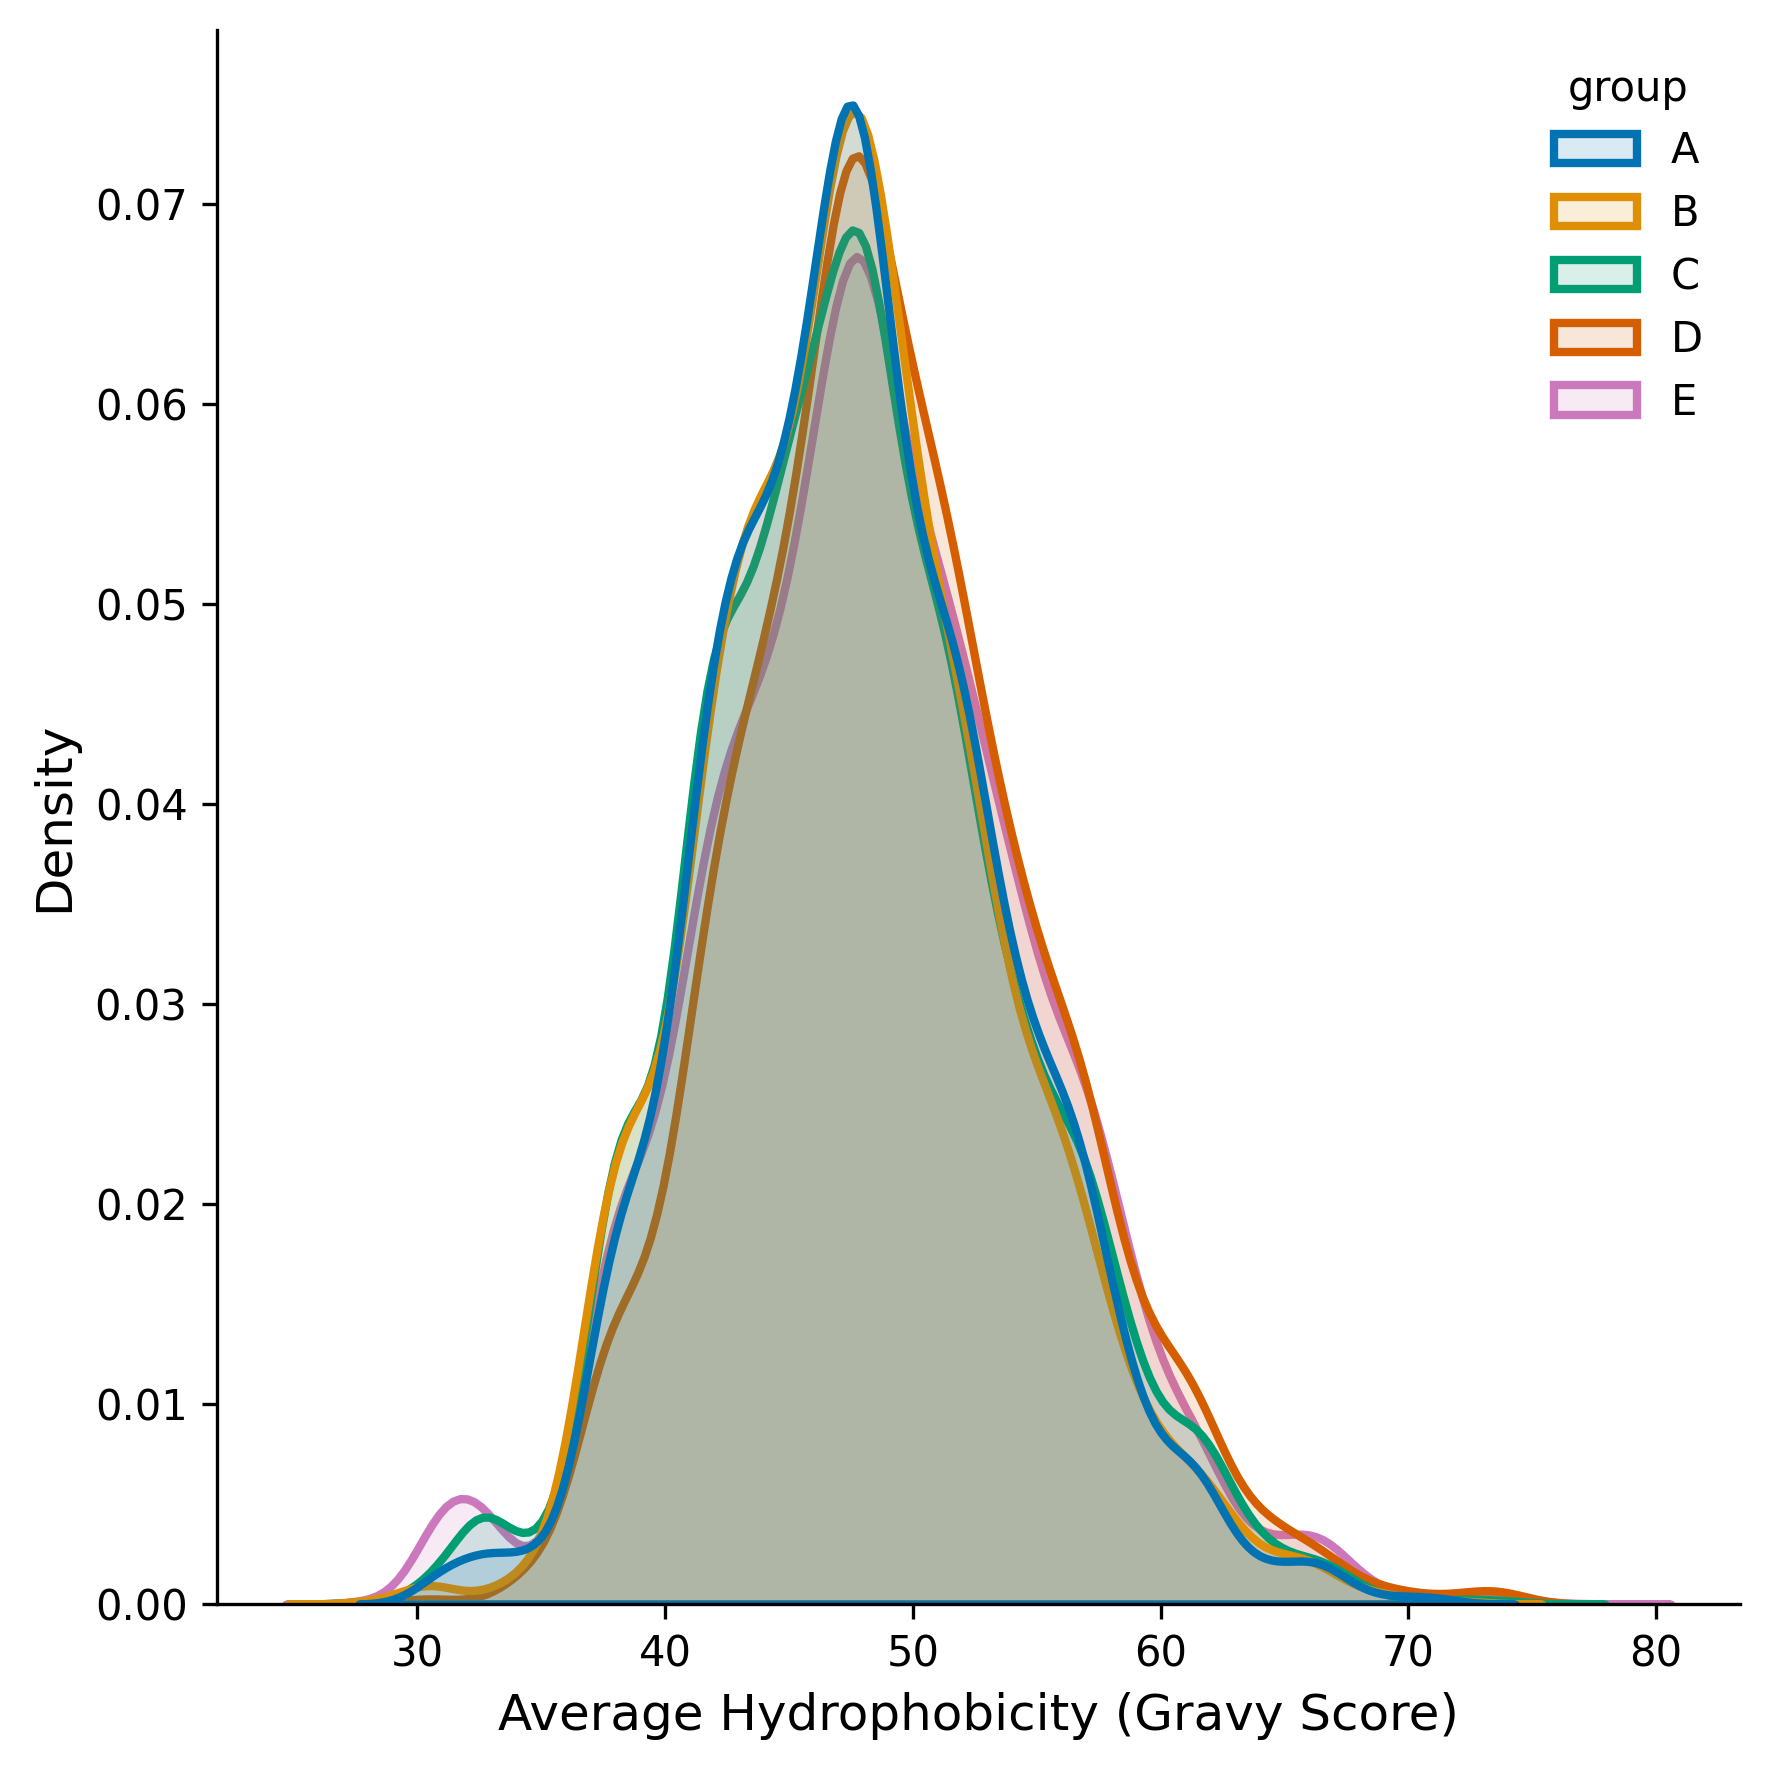

In [23]:
groups = sorted(list(set(gravy_df['group'])))

plt.figure(figsize=(6, 6), dpi=300)


palette = sns.color_palette("colorblind", len(groups))

sns.kdeplot(data = gravy_df,
    x = 'gravy score',
    hue = 'group',
    hue_order = groups,
    fill=True,
    common_norm=False,
    alpha=0.15,
    linewidth=2,
    palette=palette,
    bw_adjust=1.2
)

ax = plt.gca()
ax.legend_.set_frame_on(False)


plt.xlabel("Average Hydrophobicity (Gravy Score)", fontsize=12)
plt.ylabel("Density", fontsize=12)


sns.despine()
plt.tight_layout()


# Save the image
plt.savefig(
    "Gravy_Score_kde.jpg",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)


## 1E) Permutation Test for Hydrophobicity

### 1) Libraries Needed

In [24]:
from scipy.stats import wasserstein_distance
import numpy as np
import pandas as pd
import string
from scipy.stats import wasserstein_distance

### 2) Organize Data (Data Wrangling)

In [25]:
# import data

# File path for figure
gravy_path = './M03_raw_data_for_figures/methods_top_100_AA_index_008_var.csv'

# Import Hydrophobicity Dataframe
gravy_df = pd.read_csv(gravy_path)
gravy_df = gravy_df[['property_X', 'group', 'sample']]
gravy_df = gravy_df.rename(columns={'property_X': 'gravy score'})
# gravy_df

In [26]:


uniq_groups = sorted(list(set(gravy_df['group'])))
print(uniq_groups)
groups_list = list()

for group_i in uniq_groups:
    group_i_list = list()
    group_i_df = gravy_df[gravy_df['group'] == group_i]
    uniq_samples = list(set(group_i_df['sample']))
    for sample in uniq_samples:
        df_i = group_i_df[group_i_df['sample'] == sample]
        values_i = df_i['gravy score']
        #print (len(values_i))
        #print(type(values_i))
        group_i_list.append(values_i)
    groups_list.append(group_i_list)


print(type(groups_list))
print(len(groups_list))

print(type(groups_list[0]))
print(len(groups_list[0]))

print(type(groups_list[0][0]))
print(len(groups_list[0][0]))

['A', 'B', 'C', 'D', 'E']
<class 'list'>
5
<class 'list'>
5
<class 'pandas.core.series.Series'>
2214


### 3) Define a Reference Distribution

In [27]:
# Flatten using a nested list comprehension
flattened_values = [value for sublist1 in groups_list for sublist2 in sublist1 for value in sublist2]

# Convert to a Pandas Series
reference_distribution = np.array(flattened_values)

# Verification
print(f"Total number of values: {len(reference_distribution)}")


Total number of values: 58583


### 4) Compute the Wasserstein Distance

In [28]:

group_distances = [
    np.array([wasserstein_distance(sample, reference_distribution) for sample in group])
    for group in groups_list
]

print("Group Distances: ", group_distances)

Group Distances:  [array([0.38255401, 0.32320816, 0.45423045, 0.27289277, 0.33768625]), array([0.30698109, 0.31191843, 0.71980393, 0.57371369, 0.37716358]), array([0.16828063, 0.53351789, 0.29834755, 0.23367404, 0.54166399]), array([1.07361243, 1.18509325, 0.69336152, 0.75321504, 1.09330525]), array([0.36715969, 0.65173114, 0.29013887, 0.53729654, 0.35731333])]


### 5) Define a multi-group test statistic

For >2 groups, use between-group variance of means
(ANOVA intuition, but no assumptions).

In [29]:
def between_group_variance(groups):
    group_means = np.array([g.mean() for g in groups])
    overall_mean = np.mean(group_means)
    return np.sum((group_means - overall_mean) ** 2)


### 6) Permutation test 

Shuffle group labels at the sample level.

In [30]:
# Observed statistic
observed = between_group_variance(group_distances)

# Prepare for permutation
all_distances = np.concatenate(group_distances)
group_sizes = [len(g) for g in group_distances]

n_perm = 10_000
count = 0

for _ in range(n_perm):
    np.random.shuffle(all_distances)

    perm_groups = []
    idx = 0
    for size in group_sizes:
        perm_groups.append(all_distances[idx:idx+size])
        idx += size

    perm_stat = between_group_variance(perm_groups)
    count += perm_stat >= observed

p_value = count / n_perm
print("Permutation p-value:", p_value)


Permutation p-value: 0.0003


### 7): Effect size (important)

Report how different, not just whether.

In [31]:
effect_size = observed / np.var(all_distances, ddof=1)
print("Standardized effect size:", effect_size)


Standardized effect size: 3.356302171102061


### 8) Visualization
Distribution distances per group

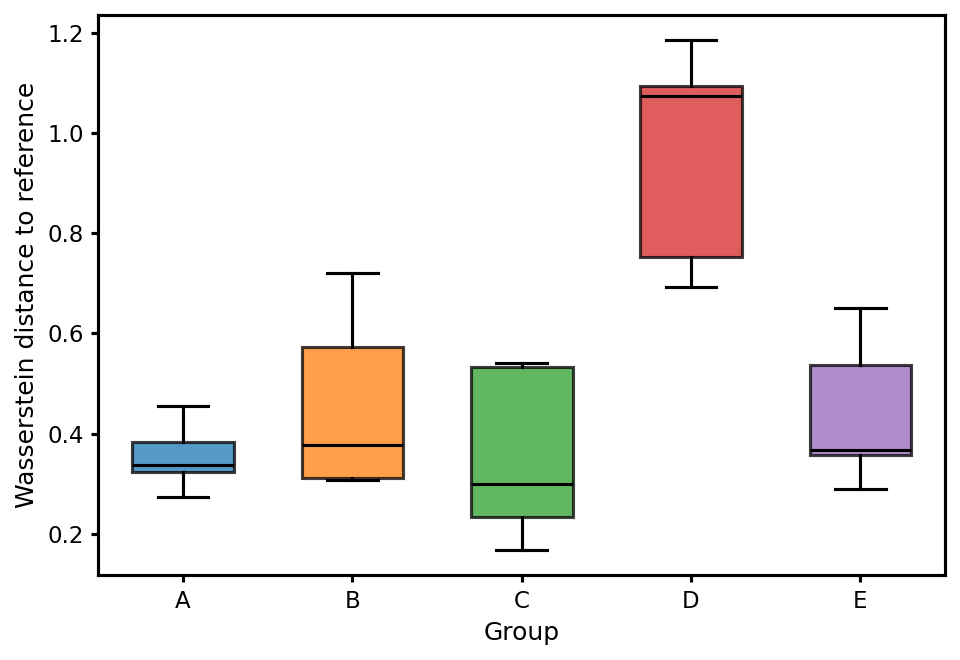

In [32]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6.5, 4.5), dpi=150)

box = ax.boxplot(
    group_distances,
    tick_labels=['A', 'B', 'C', 'D', 'E'],
    patch_artist=True,
    widths=0.6,
    showfliers=False
)

# Color boxes
colors = plt.cm.tab10.colors
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.5)

# Style whiskers, caps, medians
for element in ['whiskers', 'caps', 'medians']:
    for line in box[element]:
        line.set_color('black')
        line.set_linewidth(1.5)

# Labels and title
ax.set_ylabel("Wasserstein distance to reference", fontsize=12, color='black')
# ax.set_title("Distribution shape differences across groups", fontsize=13, pad=10)

# Remove gridlines
ax.grid(False)

# Dark axes
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')

ax.tick_params(axis='both', width=1.5, labelsize=11, colors='black')
ax.set_xlabel("Group", fontsize=12, color='black')
ax.set_ylabel("Wasserstein distance to reference", fontsize=12, color='black')
plt.tight_layout()

# Save the image
plt.savefig("Wasserstein_Distance_of_Gravy_Score.jpg", dpi=300, bbox_inches="tight", facecolor="white")

plt.show()


C:\Users\dsmal\AppData\Local\Temp\ipykernel_17072\1498979269.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(group_distances, labels=[f"G{i+1}" for i in range(5)])


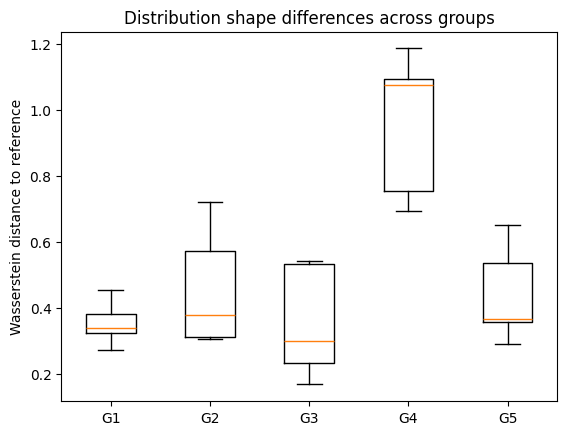

In [33]:
import matplotlib.pyplot as plt

plt.boxplot(group_distances, labels=[f"G{i+1}" for i in range(5)])
plt.ylabel("Wasserstein distance to reference")
plt.title("Distribution shape differences across groups")
plt.show()


### 9) Empirical Cumulative Distribution Function (ECDFs)

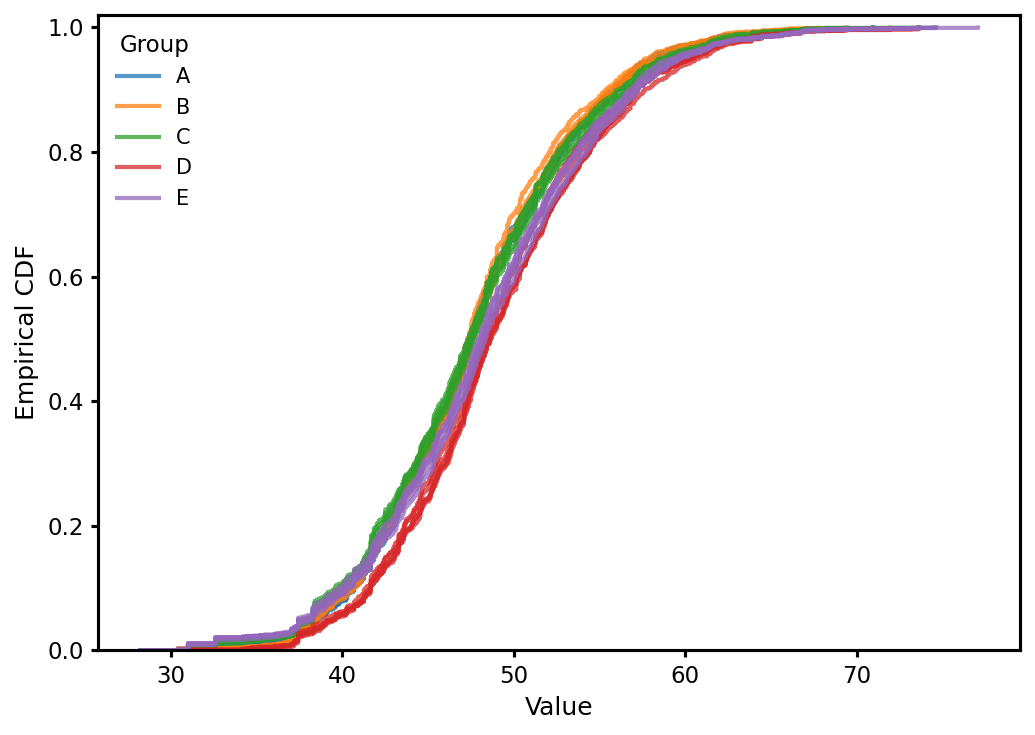

In [34]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(7, 5), dpi=150)

colors = plt.cm.tab10.colors
group_labels = ['A', 'B', 'C', 'D', 'E']

for i, group in enumerate(groups_list):
    color = colors[i % len(colors)]

    for j, sample in enumerate(group):
        sample = np.sort(sample)
        y = np.linspace(0, 1, len(sample), endpoint=False)

        ax.step(
            sample,
            y,
            where="post",
            color=color,
            alpha=0.75,
            linewidth=2,
            label=group_labels[i] if j == 0 else None
        )

# Axis labels
ax.set_xlabel("Value", fontsize=12, color="black")
ax.set_ylabel("Empirical CDF", fontsize=12, color="black")
ax.set_ylim(0, 1.02)

# Remove grid
ax.grid(False)

# Darken axes and ticks
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color("black")

ax.tick_params(
    axis='both',
    which='both',
    width=1.5,
    colors='black',
    labelsize=11
)

# Legend
ax.legend(
    title="Group",
    frameon=False,
    fontsize=10,
    title_fontsize=11
)

plt.tight_layout()


# Save the image
plt.savefig(
    "ECDF_of_Gravy_Score.jpg",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

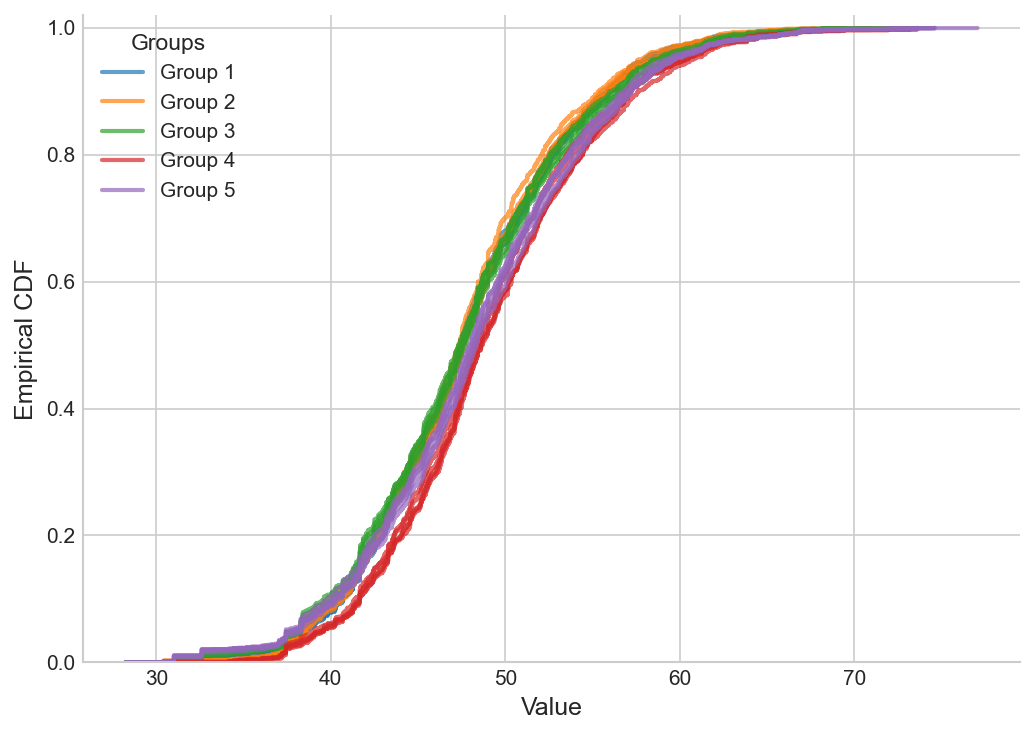

In [35]:
import matplotlib.pyplot as plt
import numpy as np

# Style + figure setup
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(7, 5), dpi=150)

colors = plt.cm.tab10.colors  # clean, distinct colors

for i, group in enumerate(groups_list):
    color = colors[i % len(colors)]

    for j, sample in enumerate(group):
        sample = np.sort(sample)
        y = np.linspace(0, 1, len(sample), endpoint=False)

        ax.step(
            sample,
            y,
            where="post",
            color=color,
            alpha=0.7,
            linewidth=2,
            label=f"Group {i+1}" if j == 0 else None
        )

# Axis labels and formatting
ax.set_xlabel("Value", fontsize=12)
ax.set_ylabel("Empirical CDF", fontsize=12)
ax.set_ylim(0, 1.02)

# Legend
ax.legend(
    title="Groups",
    frameon=False,
    fontsize=10,
    title_fontsize=11
)

# Clean up spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


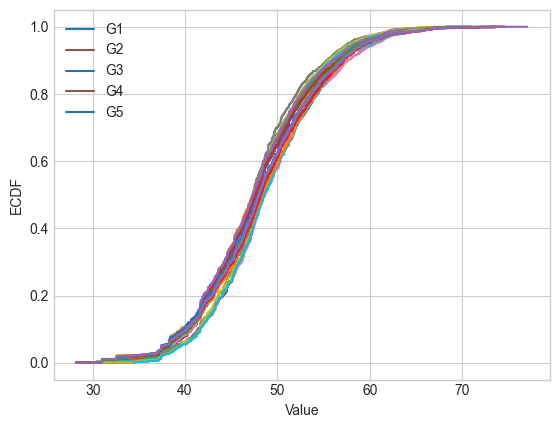

In [36]:
for i, group in enumerate(groups_list):
    for sample in group:
        plt.step(
            np.sort(sample),
            np.linspace(0, 1, len(sample)),
            alpha=1.0,
            label=f"G{i+1}" if sample is group[0] else None
        )

plt.xlabel("Value")
plt.ylabel("ECDF")
plt.legend()
plt.show()


# Example 2: NIST Samples

## 2A) Heat map of Similarity Index for Quality Assessment.

In [37]:
import pandas as pd
import numpy as np

In [38]:
# File path for figure
NIST_SI_matrix = './M03_raw_data_for_figures/NIST_set_similarity_dataframe.csv'

# Import Similarity Dataframe
NIST_similarity_matrix = pd.read_csv(NIST_SI_matrix)
NIST_similarity_matrix

,sample,1mg_1_A_1,1mg_1_A_2,1mg_1_A_3,1mg_1_B_1,1mg_1_B_2,1mg_1_B_3,1mg_1_C_1,1mg_1_C_2,1mg_1_C_3,...,1mg_7_C_3,1mg_8_A_1,1mg_8_A_2,1mg_8_A_3,1mg_8_B_1,1mg_8_B_2,1mg_8_B_3,1mg_8_C_1,1mg_8_C_2,1mg_8_C_3
0,1mg_1_A_1,1.000000,0.829234,0.820116,0.793578,0.791180,0.782135,0.761230,0.747198,0.752833,...,0.740760,0.773580,0.774376,0.779341,0.766872,0.768782,0.757095,0.675357,0.674781,0.672502
1,1mg_1_A_2,0.829234,1.000000,0.814442,0.799961,0.790578,0.790957,0.768417,0.750372,0.764673,...,0.738286,0.772811,0.770520,0.772379,0.764044,0.775127,0.755529,0.687866,0.689346,0.681931
2,1mg_1_A_3,0.820116,0.814442,1.000000,0.796721,0.795817,0.804400,0.772296,0.757644,0.767462,...,0.742001,0.774170,0.768436,0.769789,0.763708,0.777404,0.755176,0.692526,0.697949,0.688027
3,1mg_1_B_1,0.793578,0.799961,0.796721,1.000000,0.823657,0.813999,0.763857,0.752154,0.754600,...,0.726203,0.760170,0.756780,0.766428,0.771753,0.783458,0.762123,0.672913,0.667774,0.671571
4,1mg_1_B_2,0.791180,0.790578,0.795817,0.823657,1.000000,0.835669,0.771130,0.768518,0.754677,...,0.742649,0.762332,0.762119,0.772457,0.765221,0.776774,0.750892,0.691594,0.681239,0.677958
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,1mg_8_B_2,0.768782,0.775127,0.777404,0.783458,0.776774,0.786967,0.730022,0.721770,0.727418,...,0.774800,0.815069,0.804999,0.816405,0.838681,1.000000,0.818111,0.709988,0.715348,0.707980
65,1mg_8_B_3,0.757095,0.755529,0.755176,0.762123,0.750892,0.752033,0.721887,0.720891,0.715807,...,0.762498,0.809976,0.800498,0.806889,0.816743,0.818111,1.000000,0.709751,0.716694,0.706631
66,1mg_8_C_1,0.675357,0.687866,0.692526,0.672913,0.691594,0.683267,0.696191,0.686614,0.698138,...,0.722856,0.702302,0.709315,0.709803,0.705857,0.709988,0.709751,1.000000,0.807473,0.814817
67,1mg_8_C_2,0.674781,0.689346,0.697949,0.667774,0.681239,0.676387,0.696697,0.699305,0.700378,...,0.713141,0.710326,0.704849,0.724134,0.707988,0.715348,0.716694,0.807473,1.000000,0.809811


In [39]:
# Data Wrangling

# Remove the string "1mg_" from all the column names
NIST_similarity_matrix.columns = NIST_similarity_matrix.columns.str.replace('1mg_', '', regex=False)
# Strip any leading/trailing spaces that might remain.  (There shouldn't be any.)
NIST_similarity_matrix.columns = NIST_similarity_matrix.columns.str.strip()

# Remove Sonic from all the sample names
NIST_similarity_matrix['sample'] = NIST_similarity_matrix['sample'].str.replace('1mg_', '', case=False, regex=False)

# Make the sample column the index
NIST_similarity_matrix = NIST_similarity_matrix.set_index('sample')

# Replace elements below the main diagonal with NaN
NIST_similarity_matrix = NIST_similarity_matrix.where(np.triu(np.ones(NIST_similarity_matrix.shape, dtype=bool)))


# Reverse order of all columns
# similarity_matrix = similarity_matrix.iloc[:, ::-1]

NIST_similarity_matrix

,1_A_1,1_A_2,1_A_3,1_B_1,1_B_2,1_B_3,1_C_1,1_C_2,1_C_3,2_A_1,...,7_C_3,8_A_1,8_A_2,8_A_3,8_B_1,8_B_2,8_B_3,8_C_1,8_C_2,8_C_3
sample,,,,,,,,,,,,,,,,,,,,,
1_A_1,1.0,0.829234,0.820116,0.793578,0.791180,0.782135,0.761230,0.747198,0.752833,0.785459,...,0.740760,0.773580,0.774376,0.779341,0.766872,0.768782,0.757095,0.675357,0.674781,0.672502
1_A_2,NaN,1.000000,0.814442,0.799961,0.790578,0.790957,0.768417,0.750372,0.764673,0.788435,...,0.738286,0.772811,0.770520,0.772379,0.764044,0.775127,0.755529,0.687866,0.689346,0.681931
1_A_3,NaN,NaN,1.000000,0.796721,0.795817,0.804400,0.772296,0.757644,0.767462,0.804373,...,0.742001,0.774170,0.768436,0.769789,0.763708,0.777404,0.755176,0.692526,0.697949,0.688027
1_B_1,NaN,NaN,NaN,1.000000,0.823657,0.813999,0.763857,0.752154,0.754600,0.776905,...,0.726203,0.760170,0.756780,0.766428,0.771753,0.783458,0.762123,0.672913,0.667774,0.671571
1_B_2,NaN,NaN,NaN,NaN,1.000000,0.835669,0.771130,0.768518,0.754677,0.789508,...,0.742649,0.762332,0.762119,0.772457,0.765221,0.776774,0.750892,0.691594,0.681239,0.677958
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8_B_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.000000,0.818111,0.709988,0.715348,0.707980
8_B_3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.709751,0.716694,0.706631
8_C_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.807473,0.814817


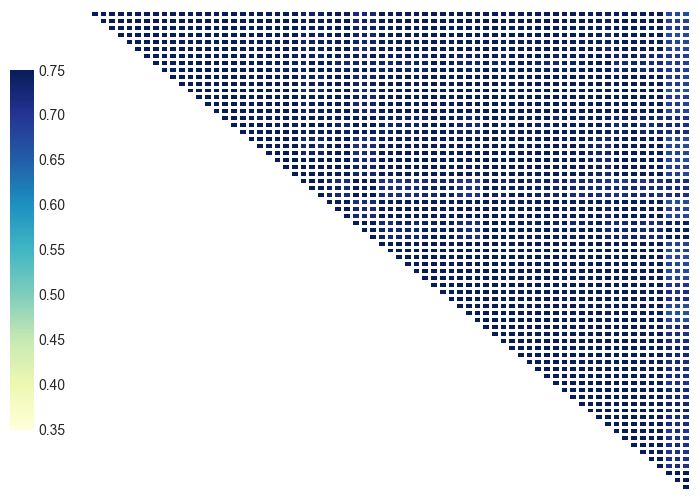

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

fig = plt.figure(figsize=(8, 6))

# Create axes: [left, bottom, width, height]
cbar_ax = fig.add_axes([0.05, 0.2, 0.03, 0.6])   # left side colorbar
ax = fig.add_axes([0.15, 0.1, 0.75, 0.8])        # main heatmap

sns.heatmap(
    NIST_similarity_matrix,
    cmap="YlGnBu",
    vmin=0.35,
    vmax=0.75, 
    linewidths=1.0,
    cbar=True,
    cbar_ax=cbar_ax,
    ax=ax
)

# Remove labels on both Axis
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")


# Saves the image as a .jpg file
plt.savefig('Heatmap_of_NIST_SI_old_index.jpg')

plt.show()


### Heatmap different scale

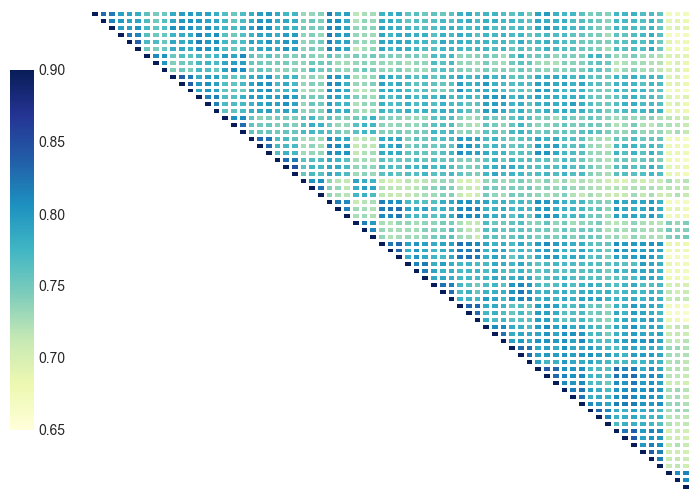

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

fig = plt.figure(figsize=(8, 6))

# Create axes: [left, bottom, width, height]
cbar_ax = fig.add_axes([0.05, 0.2, 0.03, 0.6])   # left side colorbar
ax = fig.add_axes([0.15, 0.1, 0.75, 0.8])        # main heatmap

sns.heatmap(
    NIST_similarity_matrix,
    cmap="YlGnBu",
    vmin=0.65,
    vmax=0.90, 
    linewidths=1.0,
    cbar=True,
    cbar_ax=cbar_ax,
    ax=ax
)

# Remove labels on both Axis
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")


# Saves the image as a .jpg file
plt.savefig('Heatmap_of_NIST_SI_final.jpg')

plt.show()



This figure was than imported into PowerPoint and annotated manually.  This one uses the same scale as in the previous heat map. 

## 2B) All 1mg proteins, peptides, PSM better figures

In [42]:
# File path for figure
NIST_by_group = './M03_raw_data_for_figures/NIST_top_100_summary_stats.csv'


# Import Similarity Dataframe
NIST_by_group = pd.read_csv(NIST_by_group)

# Extract numbers and create a new column
NIST_by_group['aliquot'] = NIST_by_group['group'].str[0].astype(int)
NIST_by_group['digest'] = NIST_by_group['group'].str[-1]
NIST_by_group

NIST_protein_df = NIST_by_group[NIST_by_group['property'] == 'Protein Groups']
NIST_protein_df

,Unnamed: 0,property,group,mean,sd,p_value_vs_1A,aliquot,digest
0,0,Protein Groups,1A,2435.666667,26.312228,1.000000,1,A
1,1,Protein Groups,1B,2486.333333,26.312228,0.077802,1,B
2,2,Protein Groups,1C,2315.333333,38.070111,0.010792,1,C
3,3,Protein Groups,2A,2359.666667,25.423087,0.022803,2,A
4,4,Protein Groups,2B,2384.333333,45.368859,0.165267,2,B
5,5,Protein Groups,2C,2299.000000,16.822604,0.001625,2,C
6,6,Protein Groups,3A,2470.666667,7.505553,0.091060,3,A
7,7,Protein Groups,3B,2556.000000,4.582576,0.001455,3,B
8,8,Protein Groups,3C,2384.000000,28.618176,0.082764,3,C
9,9,Protein Groups,4A,2532.000000,21.000000,0.007726,4,A


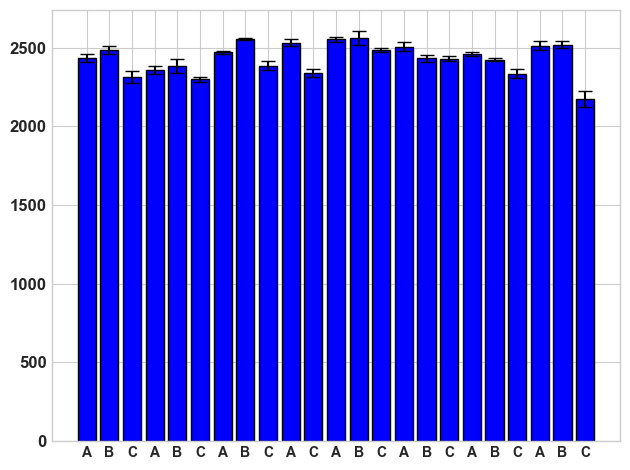

In [43]:
import matplotlib.pyplot as plt

# Create the bar chart
plt.bar(
    range(len(NIST_protein_df)),
    NIST_protein_df['mean'],
    yerr=NIST_protein_df['sd'],
    capsize=5,
    color='blue',
    edgecolor='black'
)

# Y-axis formatting
plt.yticks(fontsize=12, fontweight='bold')

# ---- SET X-TICKS USING 'digest' COLUMN ----
plt.xticks(ticks=range(len(NIST_protein_df)), labels=NIST_protein_df['digest'], fontsize=10, fontweight='bold')

plt.tight_layout()

# Save the Figure as a jpg file
plt.savefig('NIST_Proteins_per_group.jpg', dpi=300, bbox_inches='tight')
plt.show()


In [44]:
# NIST_PSM_group

NIST_PSM_df = NIST_by_group[NIST_by_group['property'] == 'PSM']
NIST_PSM_df

,Unnamed: 0,property,group,mean,sd,p_value_vs_1A,aliquot,digest
46,46,PSM,1A,20286.000000,152.587680,1.000000,1,A
47,47,PSM,1B,21184.000000,57.939624,0.000677,1,B
48,48,PSM,1C,19240.333333,253.527776,0.003609,1,C
49,49,PSM,2A,19552.666667,160.997930,0.004604,2,A
50,50,PSM,2B,19682.666667,226.753905,0.018723,2,B
51,51,PSM,2C,18834.333333,117.052695,0.000198,2,C
52,52,PSM,3A,20545.666667,93.001792,0.065575,3,A
53,53,PSM,3B,20838.666667,24.846194,0.003458,3,B
54,54,PSM,3C,18532.000000,60.893349,0.000050,3,C
55,55,PSM,4A,21199.666667,232.399082,0.004705,4,A


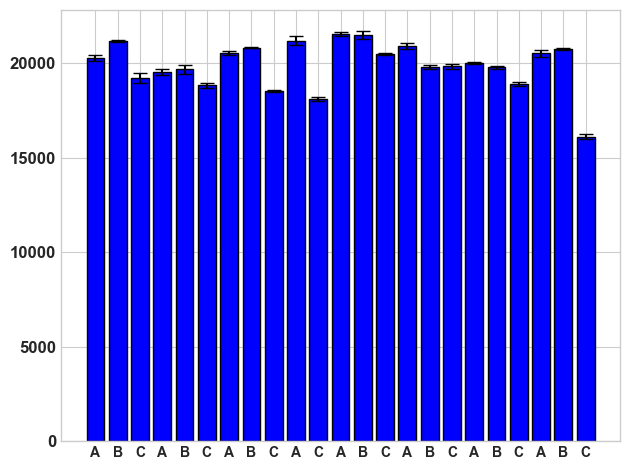

In [45]:
import matplotlib.pyplot as plt

# Create the bar chart
plt.bar(
    range(len(NIST_PSM_df)),
    NIST_PSM_df['mean'],
    yerr=NIST_PSM_df['sd'],
    capsize=5,
    color='blue',
    edgecolor='black'
)

# Y-axis formatting
plt.yticks(fontsize=12, fontweight='bold')

# ---- SET X-TICKS USING 'digest' COLUMN ----
plt.xticks(ticks=range(len(NIST_PSM_df)), labels=NIST_PSM_df['digest'], fontsize=10, fontweight='bold')

plt.tight_layout()

# Save the Figure as a jpg file
plt.savefig('NIST_PSM_per_group.jpg', dpi=300, bbox_inches='tight')
plt.show()


## 2C) CV calculations

In [46]:
import pandas as pd
import numpy as np

In [47]:
# File path for figure
NIST_all_SI_matrix = './M03_raw_data_for_figures/NIST_set_similarity_dataframe.csv'

# Import Similarity Dataframe
NIST_all_similarity_matrix = pd.read_csv(NIST_all_SI_matrix)
NIST_all_similarity_matrix

,sample,1mg_1_A_1,1mg_1_A_2,1mg_1_A_3,1mg_1_B_1,1mg_1_B_2,1mg_1_B_3,1mg_1_C_1,1mg_1_C_2,1mg_1_C_3,...,1mg_7_C_3,1mg_8_A_1,1mg_8_A_2,1mg_8_A_3,1mg_8_B_1,1mg_8_B_2,1mg_8_B_3,1mg_8_C_1,1mg_8_C_2,1mg_8_C_3
0,1mg_1_A_1,1.000000,0.829234,0.820116,0.793578,0.791180,0.782135,0.761230,0.747198,0.752833,...,0.740760,0.773580,0.774376,0.779341,0.766872,0.768782,0.757095,0.675357,0.674781,0.672502
1,1mg_1_A_2,0.829234,1.000000,0.814442,0.799961,0.790578,0.790957,0.768417,0.750372,0.764673,...,0.738286,0.772811,0.770520,0.772379,0.764044,0.775127,0.755529,0.687866,0.689346,0.681931
2,1mg_1_A_3,0.820116,0.814442,1.000000,0.796721,0.795817,0.804400,0.772296,0.757644,0.767462,...,0.742001,0.774170,0.768436,0.769789,0.763708,0.777404,0.755176,0.692526,0.697949,0.688027
3,1mg_1_B_1,0.793578,0.799961,0.796721,1.000000,0.823657,0.813999,0.763857,0.752154,0.754600,...,0.726203,0.760170,0.756780,0.766428,0.771753,0.783458,0.762123,0.672913,0.667774,0.671571
4,1mg_1_B_2,0.791180,0.790578,0.795817,0.823657,1.000000,0.835669,0.771130,0.768518,0.754677,...,0.742649,0.762332,0.762119,0.772457,0.765221,0.776774,0.750892,0.691594,0.681239,0.677958
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,1mg_8_B_2,0.768782,0.775127,0.777404,0.783458,0.776774,0.786967,0.730022,0.721770,0.727418,...,0.774800,0.815069,0.804999,0.816405,0.838681,1.000000,0.818111,0.709988,0.715348,0.707980
65,1mg_8_B_3,0.757095,0.755529,0.755176,0.762123,0.750892,0.752033,0.721887,0.720891,0.715807,...,0.762498,0.809976,0.800498,0.806889,0.816743,0.818111,1.000000,0.709751,0.716694,0.706631
66,1mg_8_C_1,0.675357,0.687866,0.692526,0.672913,0.691594,0.683267,0.696191,0.686614,0.698138,...,0.722856,0.702302,0.709315,0.709803,0.705857,0.709988,0.709751,1.000000,0.807473,0.814817
67,1mg_8_C_2,0.674781,0.689346,0.697949,0.667774,0.681239,0.676387,0.696697,0.699305,0.700378,...,0.713141,0.710326,0.704849,0.724134,0.707988,0.715348,0.716694,0.807473,1.000000,0.809811


In [48]:
# Data Wrangling

# Remove the string "1mg_" from all the column names
NIST_all_similarity_matrix.columns = NIST_all_similarity_matrix.columns.str.replace('1mg_', '', regex=False)
# Strip any leading/trailing spaces that might remain.  (There shouldn't be any.)
NIST_all_similarity_matrix.columns = NIST_all_similarity_matrix.columns.str.strip()

# Remove "1gm_" from all the sample names
NIST_all_similarity_matrix['sample'] = NIST_all_similarity_matrix['sample'].str.replace('1mg_', '', case=False, regex=False)

# Make the sample column the index
NIST_all_similarity_matrix = NIST_all_similarity_matrix.set_index('sample')

# Replace elements below the main diagonal with NaN
NIST_all_similarity_matrix = NIST_all_similarity_matrix.where(np.triu(np.ones(NIST_all_similarity_matrix.shape, dtype=bool)))


# Reverse order of all columns
# similarity_matrix = similarity_matrix.iloc[:, ::-1]

NIST_all_similarity_matrix

,1_A_1,1_A_2,1_A_3,1_B_1,1_B_2,1_B_3,1_C_1,1_C_2,1_C_3,2_A_1,...,7_C_3,8_A_1,8_A_2,8_A_3,8_B_1,8_B_2,8_B_3,8_C_1,8_C_2,8_C_3
sample,,,,,,,,,,,,,,,,,,,,,
1_A_1,1.0,0.829234,0.820116,0.793578,0.791180,0.782135,0.761230,0.747198,0.752833,0.785459,...,0.740760,0.773580,0.774376,0.779341,0.766872,0.768782,0.757095,0.675357,0.674781,0.672502
1_A_2,NaN,1.000000,0.814442,0.799961,0.790578,0.790957,0.768417,0.750372,0.764673,0.788435,...,0.738286,0.772811,0.770520,0.772379,0.764044,0.775127,0.755529,0.687866,0.689346,0.681931
1_A_3,NaN,NaN,1.000000,0.796721,0.795817,0.804400,0.772296,0.757644,0.767462,0.804373,...,0.742001,0.774170,0.768436,0.769789,0.763708,0.777404,0.755176,0.692526,0.697949,0.688027
1_B_1,NaN,NaN,NaN,1.000000,0.823657,0.813999,0.763857,0.752154,0.754600,0.776905,...,0.726203,0.760170,0.756780,0.766428,0.771753,0.783458,0.762123,0.672913,0.667774,0.671571
1_B_2,NaN,NaN,NaN,NaN,1.000000,0.835669,0.771130,0.768518,0.754677,0.789508,...,0.742649,0.762332,0.762119,0.772457,0.765221,0.776774,0.750892,0.691594,0.681239,0.677958
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8_B_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.000000,0.818111,0.709988,0.715348,0.707980
8_B_3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.709751,0.716694,0.706631
8_C_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.807473,0.814817


## 2D) NIST Peptide Length

In [49]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_ind
import matplotlib.pyplot as plt
pd.options.display.float_format = '{:.6f}'.format

In [50]:
# File path for figure
NIST_all_peptide_length_path = './M03_raw_data_for_figures/NIST_top_100_All_peptide_length_df.csv'

# Import Similarity Dataframe
peptide_length_df = pd.read_csv(NIST_all_peptide_length_path)
peptide_length_df

,Unnamed: 0,group,sample,pept_len,count
0,0,1A,1mg_1_A_1,6,438
1,1,1A,1mg_1_A_1,7,2576
2,2,1A,1mg_1_A_1,8,3151
3,3,1A,1mg_1_A_1,9,3522
4,4,1A,1mg_1_A_1,10,2925
...,...,...,...,...,...
1030,1030,8C,1mg_8_C_3,16,2073
1031,1031,8C,1mg_8_C_3,17,1301
1032,1032,8C,1mg_8_C_3,18,1209
1033,1033,8C,1mg_8_C_3,19,1447


In [51]:
uniq_peptide_lengths = list(set(peptide_length_df['pept_len']))
uniq_peptide_lengths

uniq_samples = sorted(list(set(peptide_length_df['sample'])))
uniq_samples

norm_pept_len_df = pd.DataFrame()

for sample_i in uniq_samples:
    df_i = peptide_length_df[peptide_length_df['sample'] == sample_i].copy()
    total_i = df_i['count'].sum()
    df_i['norm_count'] = df_i['count']/total_i
    norm_pept_len_df = pd.concat([norm_pept_len_df, df_i])



norm_pept_len_df

,Unnamed: 0,group,sample,pept_len,count,norm_count
0,0,1A,1mg_1_A_1,6,438,0.012784
1,1,1A,1mg_1_A_1,7,2576,0.075188
2,2,1A,1mg_1_A_1,8,3151,0.091970
3,3,1A,1mg_1_A_1,9,3522,0.102799
4,4,1A,1mg_1_A_1,10,2925,0.085374
...,...,...,...,...,...,...
1030,1030,8C,1mg_8_C_3,16,2073,0.066165
1031,1031,8C,1mg_8_C_3,17,1301,0.041524
1032,1032,8C,1mg_8_C_3,18,1209,0.038588
1033,1033,8C,1mg_8_C_3,19,1447,0.046184


In [52]:
# 1. Mean and std per pept_len and group
pept_len_summary = (
    norm_pept_len_df
    .groupby(['pept_len', 'group'])['norm_count']
    .agg(mean='mean', std='std')
    .reset_index()
)
pept_len_summary


,pept_len,group,mean,std
0,6,1A,0.011979,0.002106
1,6,1B,0.009958,0.001158
2,6,1C,0.010771,0.000421
3,6,2A,0.013786,0.003236
4,6,2B,0.012949,0.001073
...,...,...,...,...
340,20,7B,0.032750,0.000515
341,20,7C,0.030545,0.002322
342,20,8A,0.034522,0.004920
343,20,8B,0.032903,0.000681


In [53]:
pept_len_p_value_df = pd.DataFrame()
refr_group = '1A'
uniq_groups = sorted(list(set(norm_pept_len_df['group'])))

for pept_len_i in uniq_peptide_lengths:
    df_i = norm_pept_len_df[norm_pept_len_df['pept_len'] == pept_len_i]
    for group_i in uniq_groups:
        refr_values = df_i[df_i['group'] == refr_group]['count'].tolist()
        test_values = df_i[df_i['group'] == group_i]['count'].tolist()
        _, p_value = ttest_ind(refr_values, test_values, equal_var=True, alternative='two-sided')
        #row_i = pd.Series(group_i, pept_len_i, p_value)
        row_i = pd.DataFrame({'pept_len': [pept_len_i], 'group': group_i, 'p_value': p_value})
        #print("AAA", refr_values, "BBB", test_values)
        pept_len_p_value_df = pd.concat([pept_len_p_value_df, row_i])

pept_len_results_df = pd.merge(pept_len_summary, pept_len_p_value_df, on=['group', 'pept_len'], how='outer')

pept_len_results_df.to_csv('NIST_top_100_Pept_len_results.csv', index=False)
print(pept_len_results_df)






        

     pept_len group     mean      std  p_value
0           6    1A 0.011979 0.002106 1.000000
1           7    1A 0.076879 0.002694 1.000000
2           8    1A 0.093884 0.004898 1.000000
3           9    1A 0.099903 0.002651 1.000000
4          10    1A 0.085763 0.003427 1.000000
..        ...   ...      ...      ...      ...
340        16    8C 0.063715 0.002623 0.016193
341        17    8C 0.044495 0.004535 0.035758
342        18    8C 0.037991 0.002342 0.010324
343        19    8C 0.045857 0.002084 0.246872
344        20    8C 0.030648 0.001317 0.036565

[345 rows x 5 columns]


In [54]:
pept_len_pivoted_df = pept_len_results_df.pivot(index='group', columns='pept_len', values=['mean', 'std', 'p_value'])


pept_len_pivoted_df.to_csv('NIST_top_100_Pept_len_pivoted.csv', index = True)
pept_len_pivoted_df

mean                                                        \
pept_len       6        7        8        9        10       11       12   
group                                                                     
1A       0.011979 0.076879 0.093884 0.099903 0.085763 0.081011 0.091116   
1B       0.009958 0.077773 0.092984 0.101007 0.087609 0.077306 0.087347   
1C       0.010771 0.078477 0.091611 0.099480 0.092196 0.079743 0.087672   
2A       0.013786 0.075414 0.092515 0.102953 0.088665 0.084603 0.087999   
2B       0.012949 0.078662 0.092692 0.102955 0.094444 0.076736 0.091317   
2C       0.007699 0.077399 0.094411 0.099953 0.092385 0.078282 0.089689   
3A       0.009541 0.076329 0.084056 0.099961 0.086900 0.081142 0.088740   
3B       0.009976 0.077369 0.087840 0.111726 0.092607 0.080152 0.086040   
3C       0.010743 0.077476 0.097322 0.104682 0.093516 0.077160 0.089787   
4A       0.012773 0.073691 0.091796 0.105760 0.087289 0.079694 0.092257   
4C       0.010435 0.074933 0.099154 0.107061 0.097187 0.076652 0.091197   
5A       0.011121 0.079120 0.088253 0.110076 0.087484 0.081957 0.089359   
5B       0.011664 0.081936 0.086870 0.107737 0.089448 0.080064 0.086200   
5C       0.011006 0.079392 0.091713 0.101604 0.091466 0.081803 0.090674   
6A       0.010651 0.078433 0.088240 0.099291 0.089469 0.079953 0.091149   
6B       0.012267 0.074871 0.089786 0.102097 0.089036 0.081117 0.094076   
6C       0.012180 0.084960 0.089766 0.102977 0.089801 0.080731 0.094003   
7A       0.014364 0.082813 0.091061 0.099599 0.090337 0.080389 0.093001   
7B       0.010341 0.079032 0.091383 0.101360 0.091253 0.081524 0.091040   
7C       0.013120 0.077338 0.098568 0.107859 0.093707 0.078916 0.089326   
8A       0.012870 0.081336 0.091165 0.101041 0.088468 0.083880 0.091673   
8B       0.009766 0.076934 0.092014 0.106699 0.083899 0.075269 0.094249   
8C       0.009761 0.071250 0.103825 0.104904 0.094222 0.078118 0.094184   

                                     ...  p_value                             \
pept_len       13       14       15  ...       11       12       13       14   
group                                ...                                       
1A       0.080886 0.070897 0.070566  ... 1.000000 1.000000 1.000000 1.000000   
1B       0.082879 0.073366 0.070744  ... 0.788596 0.866879 0.273635 0.040780   
1C       0.082106 0.077523 0.066379  ... 0.824385 0.375663 0.642685 0.081421   
2A       0.078302 0.074819 0.065332  ... 0.517240 0.286691 0.429063 0.426974   
2B       0.077923 0.071516 0.070645  ... 0.263834 0.869995 0.655556 0.680285   
2C       0.083433 0.070314 0.071510  ... 0.180637 0.359758 0.732681 0.685278   
3A       0.083299 0.076625 0.072313  ... 0.652765 0.700341 0.556601 0.137423   
3B       0.081653 0.072962 0.069743  ... 0.527778 0.196760 0.990771 0.559540   
3C       0.084734 0.069129 0.071483  ... 0.097691 0.126787 0.880222 0.202357   
4A       0.080566 0.072374 0.069903  ... 0.954007 0.337045 0.746893 0.459978   
4C       0.077325 0.067551 0.072640  ... 0.064461 0.371410 0.117610 0.024466   
5A       0.076815 0.069684 0.068807  ... 0.241567 0.118507 0.053604 0.209168   
5B       0.084072 0.069939 0.068451  ... 0.284063 0.030903 0.811960 0.172217   
5C       0.079702 0.068864 0.072726  ... 0.795011 0.897588 0.767284 0.572757   
6A       0.077399 0.072833 0.072742  ... 0.951876 0.628211 0.567160 0.371140   
6B       0.076363 0.074348 0.069741  ... 0.433318 0.929573 0.148626 0.587043   
6C       0.086091 0.070861 0.069920  ... 0.908278 0.502449 0.247860 0.984928   
7A       0.075795 0.071502 0.068800  ... 0.537994 0.950963 0.088155 0.854544   
7B       0.081226 0.068608 0.066787  ... 0.992028 0.871535 0.958797 0.390430   
7C       0.075823 0.068497 0.074620  ... 0.268199 0.378847 0.131029 0.087790   
8A       0.081144 0.065087 0.069956  ... 0.771677 0.678387 0.664127 0.033477   
8B       0.078962 0.071741 0.072056  ... 0.026475 0.865472 0.226129 0.582436   
8C       0.073634 0.075486 0.071909  ... 0.033792 0.150458 0.0

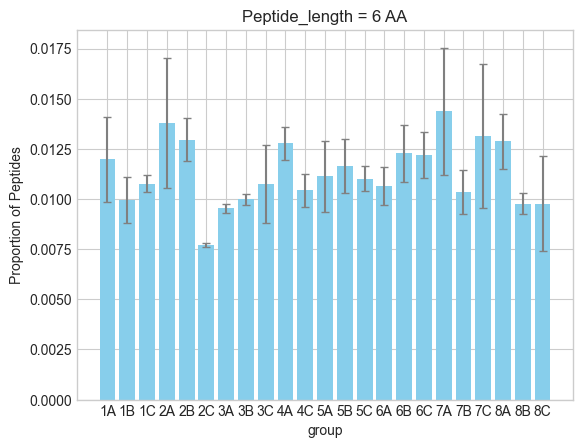

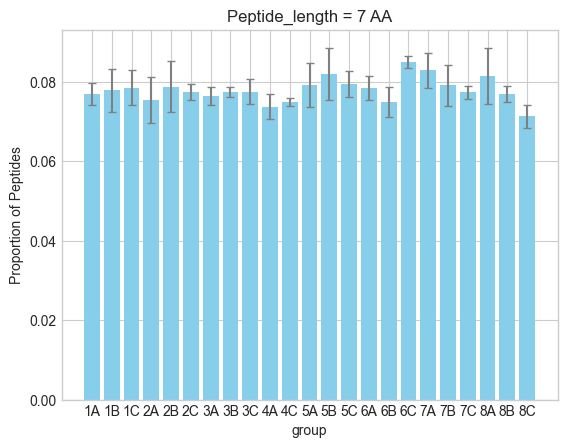

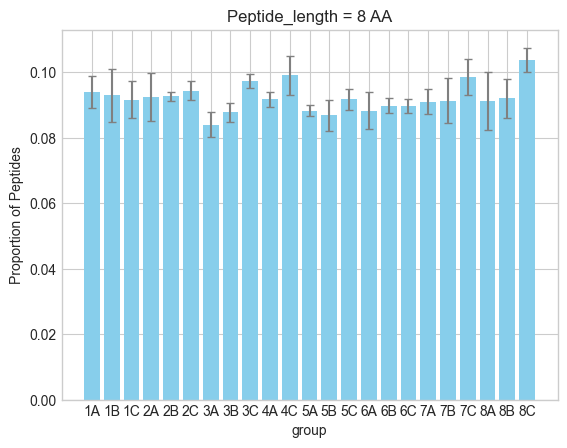

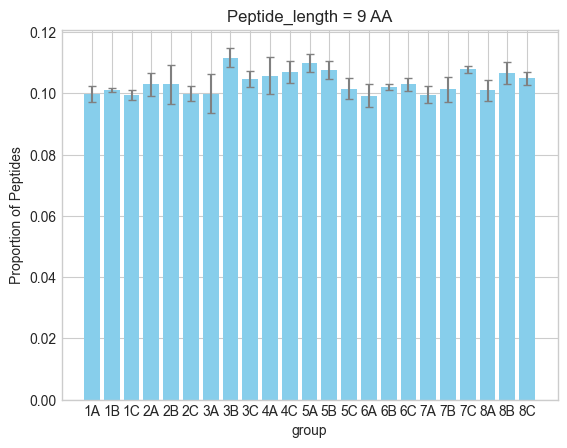

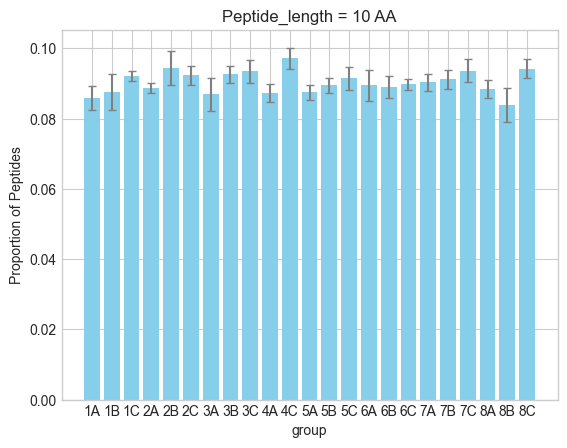

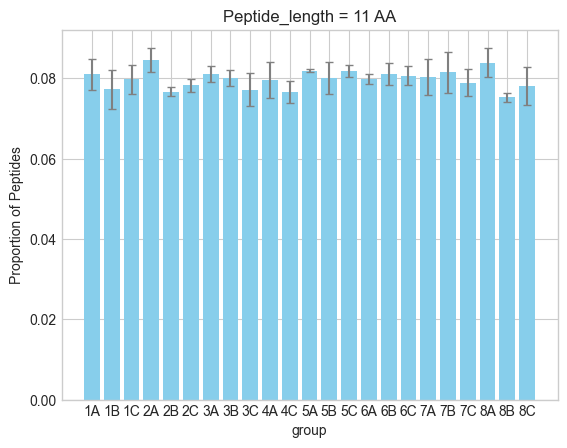

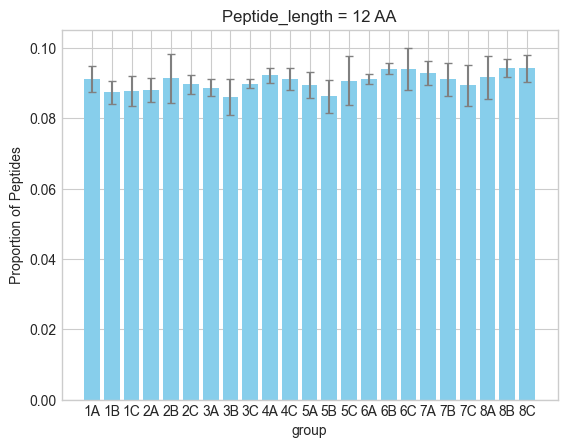

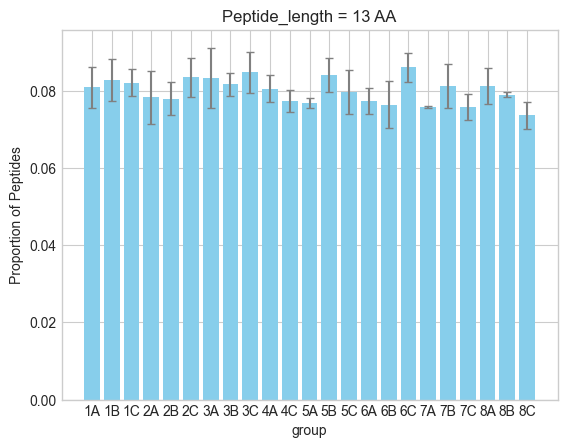

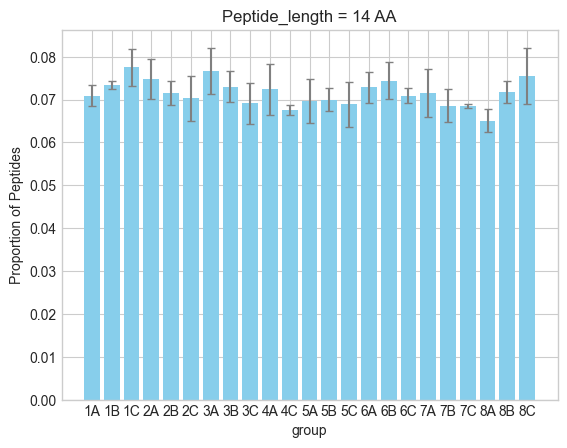

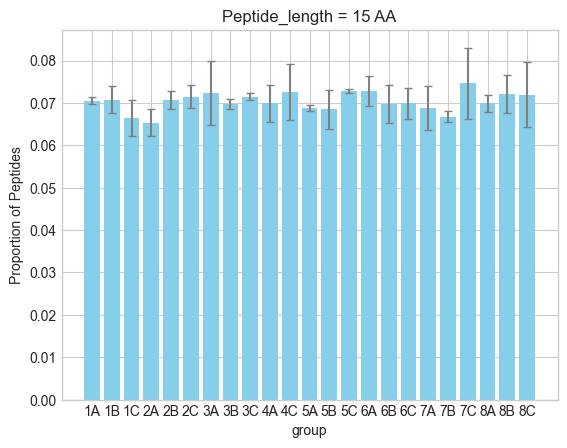

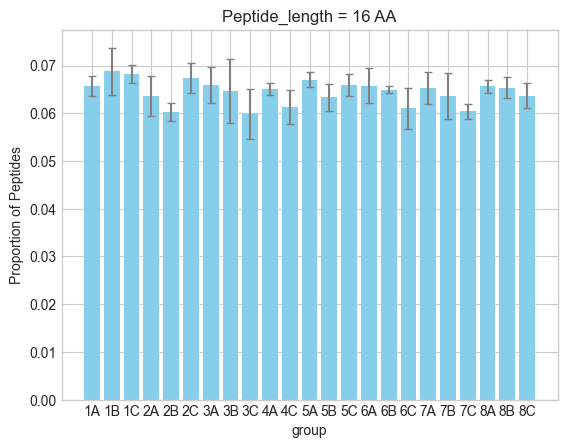

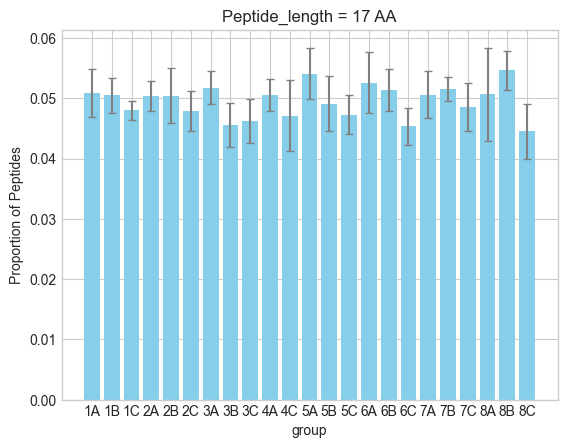

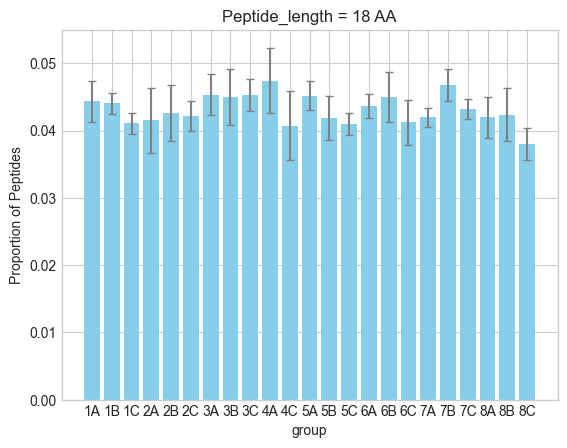

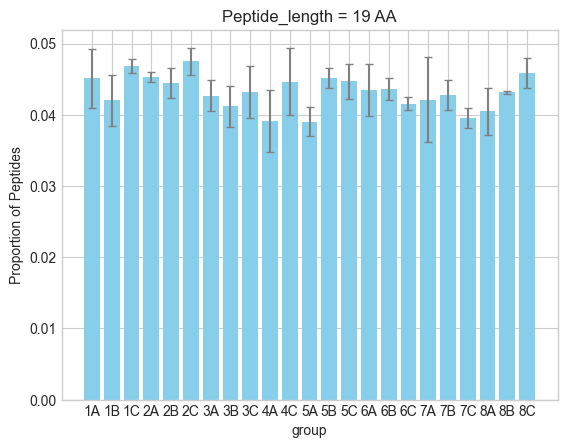

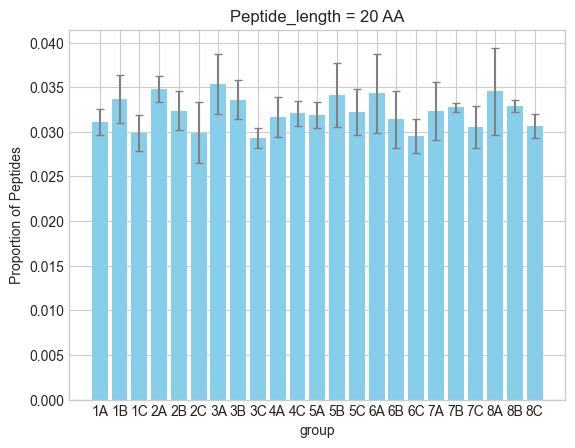

In [55]:
for pept_len_i in uniq_peptide_lengths:
    df_i = pept_len_results_df[pept_len_results_df['pept_len'] == pept_len_i]
    # Create the bar chart
    plt.bar(df_i['group'], df_i['mean'], yerr= df_i['std'], capsize=3, linewidth = 0.6, ecolor = 'grey', color='skyblue')

    # Add labels and a title
    plt.title(f'Peptide_length = {pept_len_i} AA')
    plt.xlabel('group')
    plt.ylabel('Proportion of Peptides')

    #Display the chart
    plt.show()
     

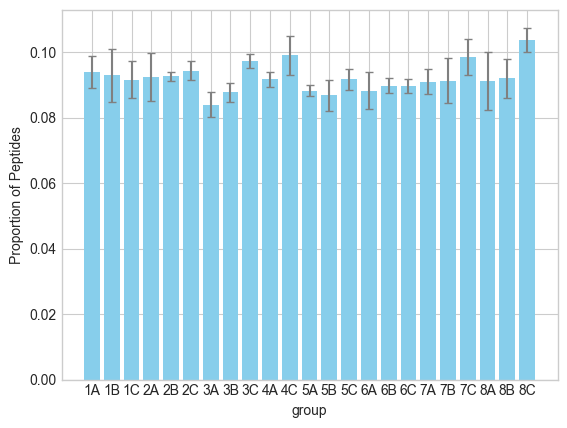

In [56]:
# Figure for paper (8AA long peptide)
df_i = pept_len_results_df[pept_len_results_df['pept_len'] == 8]
# Create the bar chart
plt.bar(df_i['group'], df_i['mean'], yerr= df_i['std'], capsize=3, linewidth = 0.6, ecolor = 'grey', color='skyblue')

# Add labels and a title

plt.xlabel('group')
plt.ylabel('Proportion of Peptides')

#Display the chart
plt.show()
     

In [57]:
df_i

,pept_len,group,mean,std,p_value
2,8,1A,0.093884,0.004898,1.000000
17,8,1B,0.092984,0.008091,0.727081
32,8,1C,0.091611,0.005645,0.759617
47,8,2A,0.092515,0.007290,0.607618
62,8,2B,0.092692,0.001379,0.874120
77,8,2C,0.094411,0.002882,0.840208
92,8,3A,0.084056,0.003685,0.075960
107,8,3B,0.087840,0.002876,0.107686
122,8,3C,0.097322,0.002233,0.953444
137,8,4A,0.091796,0.002268,0.934373


0.08825338210162205


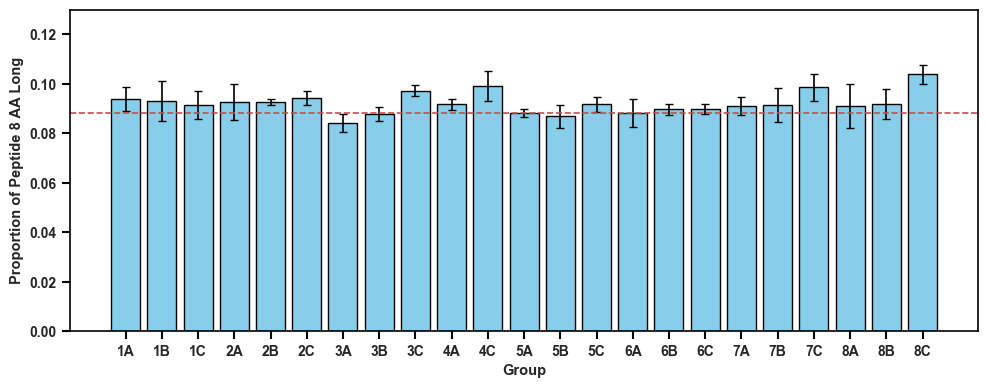

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter for 8AA long peptides
df_i = pept_len_results_df[pept_len_results_df['pept_len'] == 8]

# Set Seaborn theme for paper
sns.set_theme(context="paper", style="white", font_scale=1.1)

# Create figure
fig, ax = plt.subplots(figsize=(10,4))

# Create bar chart with error bars
bars = ax.bar(
    df_i['group'],
    df_i['mean'],
    yerr=df_i['std'],
    capsize=3,          # error bar caps
    linewidth=1.0,      # thin bar edges
    edgecolor='black',  # bar edges
    ecolor='black',      # error bar color
    color='skyblue',    # fill color
    alpha=1.0
)

# Axis labels
ax.set_xlabel('Group', fontweight='bold')
ax.set_ylabel('Proportion of Peptide 8 AA Long', fontweight='bold')

# Bold tick labels
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight('bold')

# ----- Ensure tick marks are visible -----
ax.tick_params(
    axis='x', which='both', bottom=True, top=False,
    width=1.5, length=6, color='black', direction='out', labelsize=10
)
ax.tick_params(
    axis='y', which='both', left=True, right=False,
    width=1.5, length=6, color='black', direction='out', labelsize=10
)
#y_line_value = df_i[['1A', 'mean']]
y_line_value = df_i.loc[df_i['group'] == '5A', 'mean'].values[0]

print(y_line_value)
plt.axhline(y=y_line_value, color='r', linestyle='--')
ax.set_ylim(0, 0.13)
# Dark outer border
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.savefig("8_AA_Long_figure.jpg", dpi=300, bbox_inches='tight')
plt.show()


## 2E) linking PSM to peptide length

In [59]:
# File path for figure
NIST_all_summary_path = './M03_raw_data_for_figures/NIST_top_100_All_summary_info.csv'
NIST_all_peptides_PSM = pd.read_csv(NIST_all_summary_path)
NIST_all_peptides_PSM = NIST_all_peptides_PSM.set_index('Unnamed: 0').T
NIST_all_peptides_PSM = NIST_all_peptides_PSM.reset_index()
NIST_temp = NIST_all_peptides_PSM['index'].str.split('_', expand=True)
NIST_all_peptides_PSM['group'] = NIST_temp[1] + NIST_temp[2]
NIST_all_peptides_PSM['run'] = NIST_temp[3]
#NIST_all_peptides_PSM['group'] = NIST_all_peptides_PSM['index'].str.removeprefix('1mg_')

#df['A'] = df['A'].str.extract(r'(\d).*?_([A-Z])')

#NIST_all_peptides_PSM = NIST_all_peptides_PSM.rename(columns = {'index': 'sample'})
NIST_all_peptides_PSM

Unnamed: 0,index,Protein Groups,Peptides,PSM,group,run
0,1mg_1_A_1,2419,13819,20265,1A,1
1,1mg_1_A_2,2422,13774,20145,1A,2
2,1mg_1_A_3,2466,13956,20448,1A,3
3,1mg_1_B_1,2458,14097,21133,1B,1
4,1mg_1_B_2,2491,14164,21172,1B,2
...,...,...,...,...,...,...
64,1mg_8_B_2,2500,14263,20751,8B,2
65,1mg_8_B_3,2522,14250,20751,8B,3
66,1mg_8_C_1,2124,11796,15976,8C,1
67,1mg_8_C_2,2174,11894,16144,8C,2


In [60]:
NIST_PSM_by_group = (
    NIST_all_peptides_PSM
    .groupby(['group'])['PSM']
    .agg(mean='mean', std='std')
    .reset_index()
)
NIST_PSM_by_group


,group,mean,std
0,1A,20286.000000,152.587680
1,1B,21184.000000,57.939624
2,1C,19240.333333,253.527776
3,2A,19552.666667,160.997930
4,2B,19682.666667,226.753905
5,2C,18834.333333,117.052695
6,3A,20545.666667,93.001792
7,3B,20838.666667,24.846194
8,3C,18532.000000,60.893349
9,4A,21199.666667,232.399082


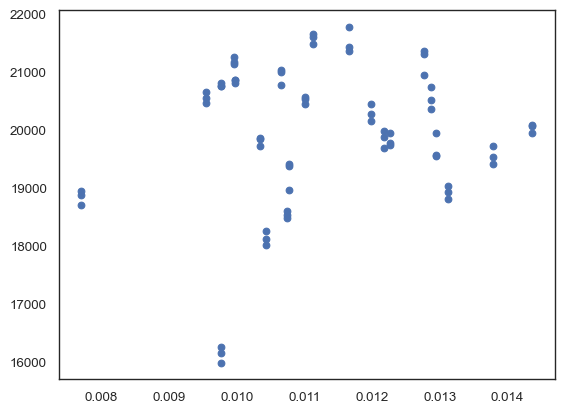

In [61]:

df_6_AA = pept_len_results_df[pept_len_results_df['pept_len'] == 6]

comparison_6_df = pd.merge(df_6_AA, NIST_all_peptides_PSM, on=['group'], how='outer')
plt.scatter(comparison_6_df['mean'], comparison_6_df['PSM'])

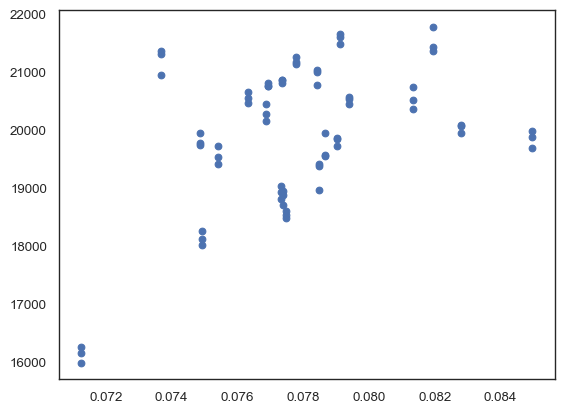

In [62]:

df_7_AA = pept_len_results_df[pept_len_results_df['pept_len'] == 7]

comparison_7_df = pd.merge(df_7_AA, NIST_all_peptides_PSM, on=['group'], how='outer')
plt.scatter(comparison_7_df['mean'], comparison_7_df['PSM'])

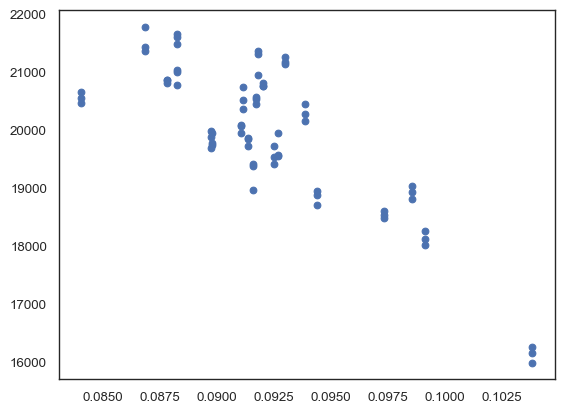

In [63]:

df_8_AA = pept_len_results_df[pept_len_results_df['pept_len'] == 8]

comparison_8_df = pd.merge(df_8_AA, NIST_all_peptides_PSM, on=['group'], how='outer')
plt.scatter(comparison_8_df['mean'], comparison_8_df['PSM'])

In [64]:
comparison_8_df

,pept_len,group,mean,std,p_value,index,Protein Groups,Peptides,PSM,run
0,8,1A,0.093884,0.004898,1.000000,1mg_1_A_1,2419,13819,20265,1
1,8,1A,0.093884,0.004898,1.000000,1mg_1_A_2,2422,13774,20145,2
2,8,1A,0.093884,0.004898,1.000000,1mg_1_A_3,2466,13956,20448,3
3,8,1B,0.092984,0.008091,0.727081,1mg_1_B_1,2458,14097,21133,1
4,8,1B,0.092984,0.008091,0.727081,1mg_1_B_2,2491,14164,21172,2
...,...,...,...,...,...,...,...,...,...,...
64,8,8B,0.092014,0.006096,0.369043,1mg_8_B_2,2500,14263,20751,2
65,8,8B,0.092014,0.006096,0.369043,1mg_8_B_3,2522,14250,20751,3
66,8,8C,0.103825,0.003746,0.940120,1mg_8_C_1,2124,11796,15976,1
67,8,8C,0.103825,0.003746,0.940120,1mg_8_C_2,2174,11894,16144,2


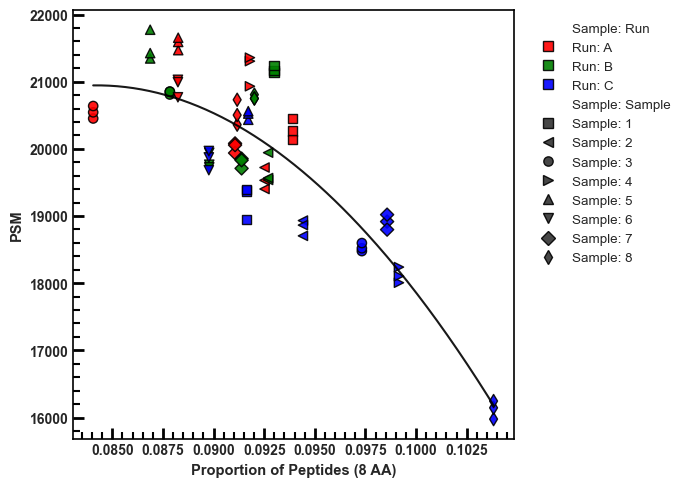

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ------------------------------------------------------------------
# Journal-style scatter plot: bold labels, pronounced ticks only on left/bottom
# ------------------------------------------------------------------

df = comparison_8_df.copy()

# Parse group labels
df['Sample'] = df['group'].str[:-1]
df['Run'] = df['group'].str[-1]

# Color mapping for Run (A / B / C)
color_map = {'A': 'red', 'B': 'green', 'C': 'blue'}

# Marker shapes (empty/filled)
marker_cycle = ['s','<','o','>','^','v','D','d']
unique_samples = sorted(df['Sample'].unique())
marker_map = {sample: marker_cycle[i % len(marker_cycle)] for i, sample in enumerate(unique_samples)}

# Seaborn theme
sns.set_theme(context="paper", style="white", font_scale=1.1)
fig, ax = plt.subplots(figsize=(7,5))

# Scatter plot
sns.scatterplot(
    data=df,
    x='mean',
    y='PSM',
    hue='Run',
    style='Sample',
    palette=color_map,
    markers=marker_map,
    s=45,
    alpha=0.9,
    linewidth=1.0,
    edgecolor='black',
    ax=ax,
    legend='brief'
)

# Quadratic fit
x = df['mean'].values
y = df['PSM'].values
coeffs = np.polyfit(x, y, deg=2)
poly_fn = np.poly1d(coeffs)
x_fit = np.linspace(x.min(), x.max(), 200)
y_fit = poly_fn(x_fit)
ax.plot(x_fit, y_fit, color='black', linewidth=1.5, alpha=0.9, label='_nolegend_')

# Axis labels bold
ax.set_xlabel('Proportion of Peptides (8 AA)', fontweight='bold')
ax.set_ylabel('PSM', fontweight='bold')

# ----- Ticks: only bottom (x) and left (y), bold and pronounced -----
ax.tick_params(
    axis='x', which='both', bottom=True, top=False, width=2, length=8,
    direction='in', color='black', labelsize=10
)
ax.tick_params(
    axis='y', which='both', left=True, right=False, width=2, length=8,
    direction='in', color='black', labelsize=10
)

# Minor ticks visible only on left/bottom
ax.minorticks_on()
ax.tick_params(which='minor', axis='x', bottom=True, top=False, width=1.5, length=5, direction='in', color='black')
ax.tick_params(which='minor', axis='y', left=True, right=False, width=1.5, length=5, direction='in', color='black')

# Bold tick labels
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight('bold')

# Legend formatting
handles, labels = ax.get_legend_handles_labels()
new_labels = ['Run: ' + label if label in ['A','B','C'] else 'Sample: ' + label for label in labels]
ax.legend(handles, new_labels, frameon=False, bbox_to_anchor=(1.02,1), loc='upper left')

# Dark outer border
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(1.2)


    

plt.tight_layout()

plt.savefig("correlation_PSM_8_AA_peptides.jpg", dpi=300, bbox_inches='tight')
plt.show()


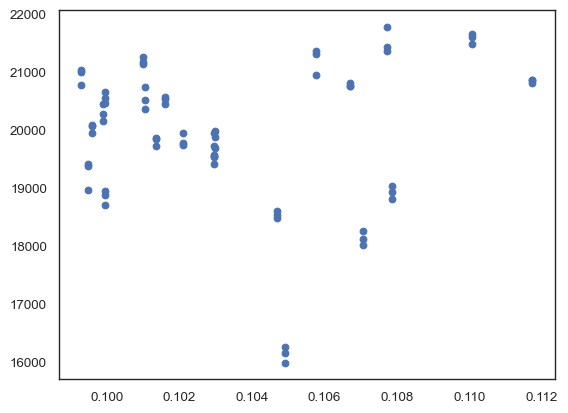

In [66]:

df_9_AA = pept_len_results_df[pept_len_results_df['pept_len'] == 9]

comparison_9_df = pd.merge(df_9_AA, NIST_all_peptides_PSM, on=['group'], how='outer')
plt.scatter(comparison_9_df['mean'], comparison_8_df['PSM'])

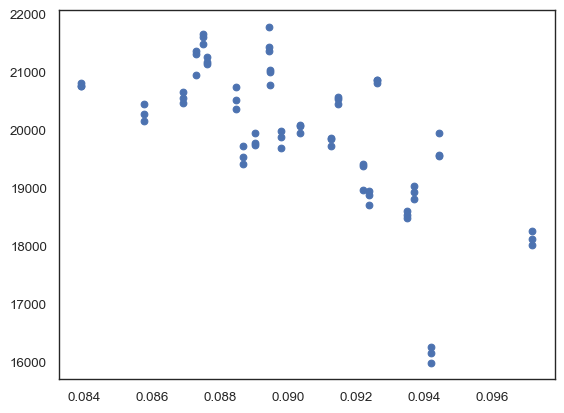

In [67]:


df_10_AA = pept_len_results_df[pept_len_results_df['pept_len'] == 10]
df_10_AA

comparison_10_df = pd.merge(df_10_AA, NIST_all_peptides_PSM, on=['group'], how='outer')
comparison_10_df
plt.scatter(comparison_10_df['mean'], comparison_10_df['PSM'])

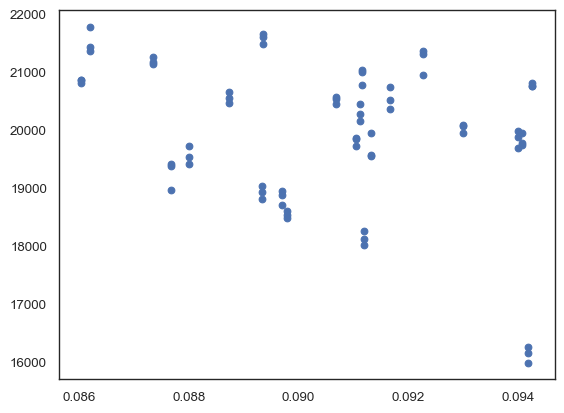

In [68]:


df_12_AA = pept_len_results_df[pept_len_results_df['pept_len'] == 12]
df_12_AA

comparison_12_df = pd.merge(df_12_AA, NIST_all_peptides_PSM, on=['group'], how='outer')
comparison_12_df
plt.scatter(comparison_12_df['mean'], comparison_12_df['PSM'])

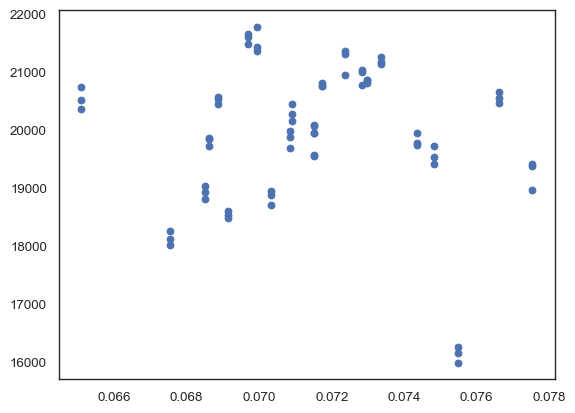

In [69]:


df_14_AA = pept_len_results_df[pept_len_results_df['pept_len'] == 14]
df_14_AA

comparison_14_df = pd.merge(df_14_AA, NIST_all_peptides_PSM, on=['group'], how='outer')
comparison_14_df
plt.scatter(comparison_14_df['mean'], comparison_14_df['PSM'])

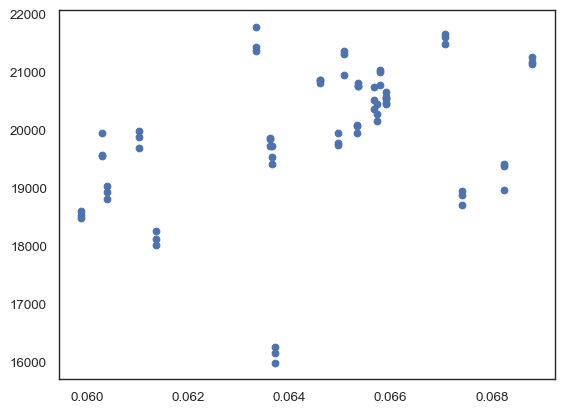

In [70]:


df_16_AA = pept_len_results_df[pept_len_results_df['pept_len'] == 16]
df_16_AA

comparison_16_df = pd.merge(df_16_AA, NIST_all_peptides_PSM, on=['group'], how='outer')
comparison_16_df
plt.scatter(comparison_16_df['mean'], comparison_16_df['PSM'])

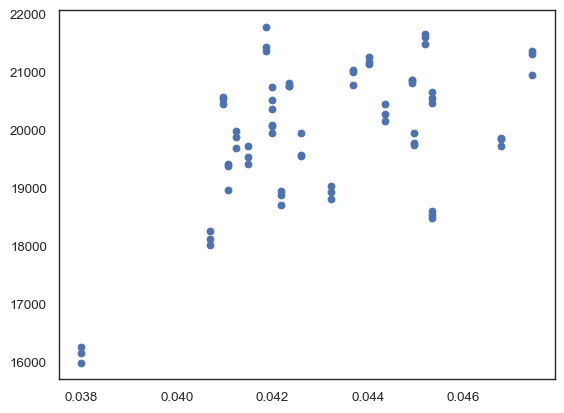

In [71]:


df_18_AA = pept_len_results_df[pept_len_results_df['pept_len'] == 18]
df_18_AA

comparison_18_df = pd.merge(df_18_AA, NIST_all_peptides_PSM, on=['group'], how='outer')
comparison_18_df
plt.scatter(comparison_18_df['mean'], comparison_18_df['PSM'])

## 2F) MW distribution -   

In [72]:
# File path for figure
NIST_all_MW_path = './M03_raw_data_for_figures/NIST_top_100_All_MW_df.csv'

# Import Similarity Dataframe
MW_df = pd.read_csv(NIST_all_MW_path)
MW_df

,Unnamed: 0,MW,sample,group
0,0,1999.096289,1mg_1_A_1,1A
1,1,771.431332,1mg_1_A_1,1A
2,2,771.431332,1mg_1_A_1,1A
3,3,2058.884073,1mg_1_A_1,1A
4,4,2058.884073,1mg_1_A_1,1A
...,...,...,...,...
2337850,2337850,1457.672786,1mg_8_C_3,8C
2337851,2337851,1185.591740,1mg_8_C_3,8C
2337852,2337852,1185.591740,1mg_8_C_3,8C
2337853,2337853,1185.591740,1mg_8_C_3,8C


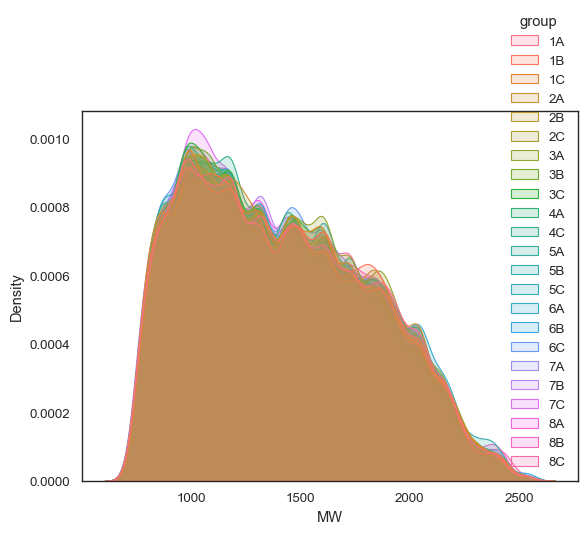

In [73]:
import seaborn as sns
sns.kdeplot(data = MW_df, x = 'MW', hue='group', fill=True, 
                common_norm=False, alpha=0.2)


sns.move_legend(ax, "center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.savefig("NIST_Density_plot_all_groups.jpg", dpi=300, bbox_inches='tight')
   

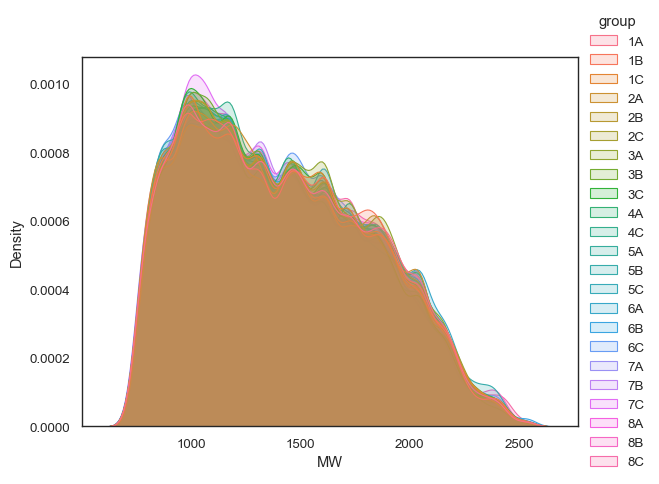

In [74]:
import seaborn as sns
import matplotlib.pyplot as plt

ax = sns.kdeplot(
    data=MW_df,
    x='MW',
    hue='group',
    fill=True,
    common_norm=False,
    alpha=0.2
)

# Move legend outside to the right
sns.move_legend(
    ax,
    "center left",
    bbox_to_anchor=(1, 0.5),
    frameon=False
)

plt.savefig("NIST_Density_plot_all_groups_2.jpg", dpi=300, bbox_inches='tight')
plt.show()




In [75]:

#Lets only look at the 3 with the highest number of PSMs and 3 with the lowest number of PSMs.

sorted_NIST_PSM = NIST_PSM_by_group.sort_values(by = 'mean')

sorted_NIST_PSM


# worst are 3C, 4C, and 8C
# Best are 4A, 5A, 5B

,group,mean,std
22,8C,16121.666667,135.883529
10,4C,18117.333333,116.988603
8,3C,18532.000000,60.893349
5,2C,18834.333333,117.052695
19,7C,18912.333333,111.607945
2,1C,19240.333333,253.527776
3,2A,19552.666667,160.997930
4,2B,19682.666667,226.753905
18,7B,19798.666667,77.719581
15,6B,19811.333333,115.682035


In [76]:
# Select only the runs of interest
runs_of_interest = ['3C', '4C', '8C', '4A', '5A', '5B']

# worst are 3C, 4C, and 8C
# Best are 4A, 5A, 5B


filtered_MW_df = MW_df[MW_df['group'].isin(runs_of_interest)]

print(filtered_MW_df)

         Unnamed: 0          MW     sample group
827779       827779 1999.096289  1mg_3_C_1    3C
827780       827780  771.431332  1mg_3_C_1    3C
827781       827781  771.431332  1mg_3_C_1    3C
827782       827782 1305.675090  1mg_3_C_1    3C
827783       827783 1305.675090  1mg_3_C_1    3C
...             ...         ...        ...   ...
2337850     2337850 1457.672786  1mg_8_C_3    8C
2337851     2337851 1185.591740  1mg_8_C_3    8C
2337852     2337852 1185.591740  1mg_8_C_3    8C
2337853     2337853 1185.591740  1mg_8_C_3    8C
2337854     2337854 1185.591740  1mg_8_C_3    8C

[593139 rows x 4 columns]


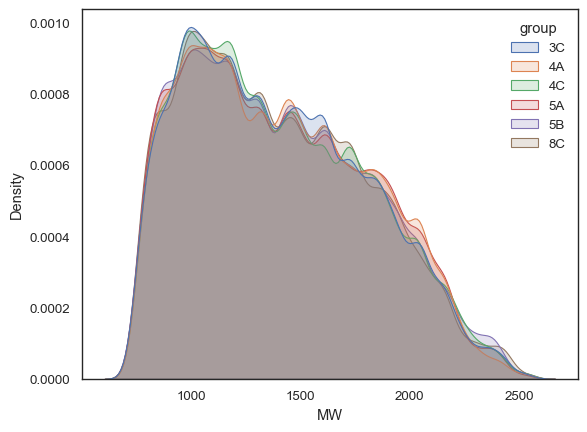

In [77]:
import seaborn as sns
sns.kdeplot(data = filtered_MW_df, x = 'MW', hue='group', fill=True, 
                common_norm=False, alpha=0.2)

plt.savefig("Density_plot_6_sample.jpg", dpi=300, bbox_inches='tight')
# worst are 3C, 4C, and 8C
# Best are 4B, 5A, 5B   

## 2G) Box Plot for MW distibution


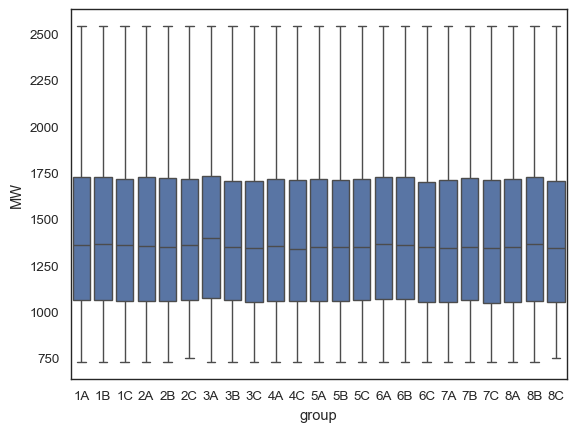

In [78]:
import seaborn
sns.boxplot(y = "MW", x="group", data=MW_df)


plt.savefig("NIST_Boxplot_MS_distribution.jpg", dpi=300, bbox_inches='tight')
plt.show()

In [79]:
MW_df

,Unnamed: 0,MW,sample,group
0,0,1999.096289,1mg_1_A_1,1A
1,1,771.431332,1mg_1_A_1,1A
2,2,771.431332,1mg_1_A_1,1A
3,3,2058.884073,1mg_1_A_1,1A
4,4,2058.884073,1mg_1_A_1,1A
...,...,...,...,...
2337850,2337850,1457.672786,1mg_8_C_3,8C
2337851,2337851,1185.591740,1mg_8_C_3,8C
2337852,2337852,1185.591740,1mg_8_C_3,8C
2337853,2337853,1185.591740,1mg_8_C_3,8C


## 2H) Differences in Distribution of MW for select Groups

### 1) Libraries Needed

In [80]:
from scipy.stats import wasserstein_distance
import numpy as np
import pandas as pd
import string
from scipy.stats import wasserstein_distance

### 2) Data Wrangling

In [81]:
group_3C = MW_df[MW_df['group'] == '3C']['MW'].tolist()
group_4C = MW_df[MW_df['group'] == '4C']['MW'].tolist()
group_8C = MW_df[MW_df['group'] == '8C']['MW'].tolist()
group_5A = MW_df[MW_df['group'] == '5A']['MW'].tolist()    
group_5B = MW_df[MW_df['group'] == '5B']['MW'].tolist()
group_4A = MW_df[MW_df['group'] == '4A']['MW'].tolist()

# worst are 3C, 4C, and 8C
# Best are 4B, 5A, 5B  

groups_list = list([group_3C, group_4C, group_8C, group_5B, group_4A])
len(groups_list)

5

In [82]:
print(len(groups_list[0]))
print(len(groups_list[1]))
print(len(groups_list[2]))
print(len(groups_list[3]))
print(len(groups_list[4]))

99269
99506
93559
97633
105098


### 3) Define a Reference Population

In [83]:
# Use the group that has the most PSM = 5A

reference_distribution = group_5A

### 4) Compute the Wasserstein Distance

In [84]:
# worst are 3C, 4C, and 8C
# Best are 4B, 5A, 5B 

print(wasserstein_distance(group_3C, reference_distribution))
print(wasserstein_distance(group_4C, reference_distribution))
print(wasserstein_distance(group_8C, reference_distribution))
print(wasserstein_distance(group_4A, reference_distribution))
# print(wasserstein_distance(group_5A, reference_distribution))
print(wasserstein_distance(group_5B, reference_distribution))

10.101459666006404
9.855919803462962
9.962974706918255
4.225954205759906
4.667227122745199


In [85]:
from scipy.stats import wasserstein_distance
import numpy as np

# Sample data from two 1D distributions
u_values = np.array([1, 2, 3, 4])
v_values = np.array([2, 3, 4, 5])

# Compute the Wasserstein distance (unweighted, assumes uniform weights)
distance = wasserstein_distance(u_values, v_values)
print(f"Wasserstein distance: {distance}")

# Example with weights (e.g., histograms)
u_weights = np.array([0.25, 0.25, 0.25, 0.25])
v_weights = np.array([0.1, 0.2, 0.3, 0.4])
weighted_distance = wasserstein_distance(u_values, v_values, u_weights, v_weights)
print(f"Weighted Wasserstein distance: {weighted_distance}")


Wasserstein distance: 1.0
Weighted Wasserstein distance: 1.5


In [86]:

group_distances = [
    np.array([wasserstein_distance(sample, reference_distribution) for sample in groups_list])
]

print("Group Distances: ", group_distances)

Group Distances:  [array([10.10145967,  9.8559198 ,  9.96297471,  4.66722712,  4.22595421])]


### 6) Make a ECDF plot

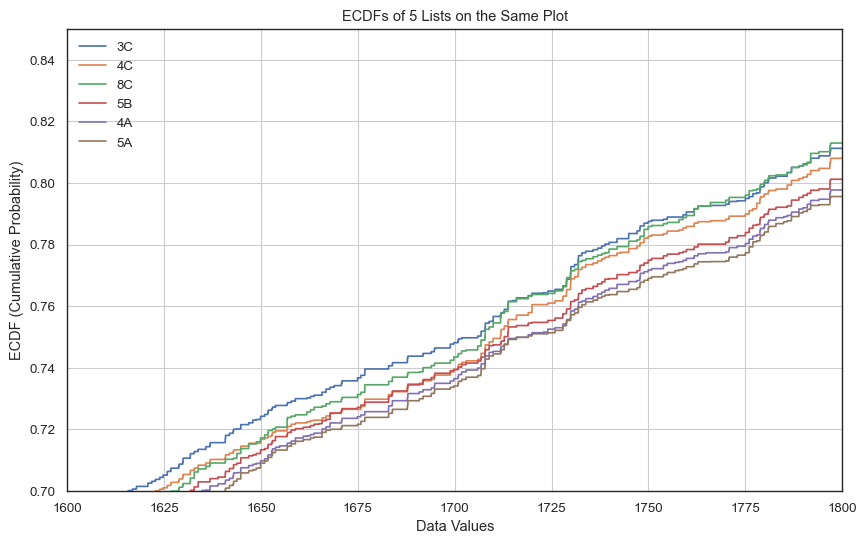

In [87]:
selected_groups = list([group_3C, group_4C, group_8C, group_5B, group_4A, group_5A])
selected_labels = ['3C', '4C', '8C', '5B', '4A', '5A']

# 2. Create the plot
plt.figure(figsize=(10, 6)) 

for data, label in zip(selected_groups, selected_labels):
    sns.ecdfplot(data, label=label) # Plots ECDF for each list on the same axes

plt.xlim(1600, 1800)
plt.ylim(0.7, 0.85)


# 3. Add labels, title, and a legend
plt.xlabel('Data Values')
plt.ylabel('ECDF (Cumulative Probability)')
plt.title('ECDFs of 5 Lists on the Same Plot')
plt.legend()
plt.grid(True)
plt.show()




## 2I) Examine all runs for selected groups - Distribution

### 1) Libraries Needed
All loaded above

### 2) Data Wrangling

In [88]:
group_3C = MW_df[MW_df['group'] == '3C']['MW'].tolist()
group_4C = MW_df[MW_df['group'] == '4C']['MW'].tolist()
group_8C = MW_df[MW_df['group'] == '8C']['MW'].tolist()
group_5A = MW_df[MW_df['group'] == '5A']['MW'].tolist()    
group_5B = MW_df[MW_df['group'] == '5B']['MW'].tolist()
group_4A = MW_df[MW_df['group'] == '4A']['MW'].tolist()

# worst are 3C, 4C, and 8C
# Best are 4B, 5A, 5B  

groups_list = list([group_3C, group_4C, group_8C, group_5B, group_4A])
len(groups_list)

5

In [89]:
filtered_MW_df = MW_df[MW_df['group'].isin(['3C', '4C', '8C', '5A', '5B', '4A'])]
filtered_MW_df = filtered_MW_df.sort_values(by='sample')
filtered_MW_df


,Unnamed: 0,MW,sample,group
827779,827779,1999.096289,1mg_3_C_1,3C
850055,850055,2321.205554,1mg_3_C_1,3C
850054,850054,2321.205554,1mg_3_C_1,3C
850053,850053,1833.911753,1mg_3_C_1,3C
850052,850052,728.406841,1mg_3_C_1,3C
...,...,...,...,...
2316960,2316960,1670.913755,1mg_8_C_3,8C
2316959,2316959,1670.913755,1mg_8_C_3,8C
2316958,2316958,1670.913755,1mg_8_C_3,8C
2316956,2316956,1670.913755,1mg_8_C_3,8C


In [90]:


# 1. Group by BOTH 'group' and 'sample' to get a list for each sample
sample_lists = filtered_MW_df.groupby(['group', 'sample'])['MW'].apply(list)
print(sample_lists)


# 2. Group by 'group' only to nest those sample lists into a list of lists
final_nested_lists = sample_lists.groupby('group').apply(list).tolist()
print(len(final_nested_lists))
print(len(final_nested_lists[3]))
print(len(final_nested_lists[3][2]))
# 3C, 4A, 4C, 5A, 5B, 8C

group  sample   
3C     1mg_3_C_1    [1999.096289, 2321.205554, 2321.205554, 1833.9...
       1mg_3_C_2    [875.450101, 1848.039647, 875.450101, 1848.039...
       1mg_3_C_3    [892.491908, 1074.4917, 892.491908, 1074.4917,...
4A     1mg_4_A_1    [1197.533618, 1020.461113, 855.5065510000001, ...
       1mg_4_A_2    [903.454903, 903.454903, 903.454903, 1859.0417...
       1mg_4_A_3    [1264.688766, 1886.963223, 1886.963223, 1651.8...
4C     1mg_4_C_1    [1928.000327, 1988.930199, 1210.7285009999998,...
       1mg_4_C_2    [1132.518312, 2084.9803, 1570.838896, 1570.838...
       1mg_4_C_3    [1790.977796, 983.48113, 983.48113, 983.48113,...
5A     1mg_5_A_1    [1522.773952, 1522.773952, 1522.773952, 1522.7...
       1mg_5_A_2    [1988.930199, 1988.930199, 890.4861460000001, ...
       1mg_5_A_3    [1124.4985699999995, 1573.814765, 2155.090924,...
5B     1mg_5_B_1    [1173.52373, 1173.52373, 1173.52373, 1173.5237...
       1mg_5_B_2    [1075.591346, 1075.591346, 1075.591346, 1075.5...
   

### 3) Define a Reference Population

In [91]:
"""
# Flatten using a nested list comprehension
flattened_values = [value for sublist1 in final_nested_lists for sublist2 in sublist1 for value in sublist2]

# Convert to a Pandas Series
reference_distribution = np.array(flattened_values)
len(reference_distribution)
"""

'\n# Flatten using a nested list comprehension\nflattened_values = [value for sublist1 in final_nested_lists for sublist2 in sublist1 for value in sublist2]\n\n# Convert to a Pandas Series\nreference_distribution = np.array(flattened_values)\nlen(reference_distribution)\n'

In [92]:

# simply using 1 of the runs from the group with the highest number of PSMs
# best run was 5A
reference_population = final_nested_lists[3][2]
print(reference_population[0:10])
print(len(reference_population))


[1124.4985699999995, 1573.814765, 2155.090924, 2155.090924, 2155.090924, 1340.624818, 1340.624818, 1367.7336389999998, 1308.598614, 1573.814765]
32630


### 4) Compute the Wasserstein Distance

In [93]:

group_distances = [
    np.array([wasserstein_distance(sample, reference_distribution) for sample in group])
    for group in final_nested_lists
]

print("Group Distances: ", group_distances)

Group Distances:  [array([ 8.61925053, 10.21592739, 13.7310928 ]), array([5.73895098, 7.97082337, 5.36048358]), array([ 7.58083372,  9.31455567, 18.54724316]), array([2.8585344 , 7.07710487, 6.62992101]), array([4.86217174, 6.96087573, 8.41434837]), array([11.1631972 ,  7.02016919, 16.40165814])]


### 5) Define a multi-group test statistic

For >2 groups, use between-group variance of means
(ANOVA intuition, but no assumptions).

In [94]:
def between_group_variance(groups):
    group_means = np.array([g.mean() for g in groups])
    overall_mean = np.mean(group_means)
    return np.sum((group_means - overall_mean) ** 2)


### 6) Permutation test 

Shuffle group labels at the sample level.

In [95]:
# Observed statistic
observed = between_group_variance(group_distances)

# Prepare for permutation
all_distances = np.concatenate(group_distances)
group_sizes = [len(g) for g in group_distances]

n_perm = 10_000
count = 0

for _ in range(n_perm):
    np.random.shuffle(all_distances)

    perm_groups = []
    idx = 0
    for size in group_sizes:
        perm_groups.append(all_distances[idx:idx+size])
        idx += size

    perm_stat = between_group_variance(perm_groups)
    count += perm_stat >= observed

p_value = count / n_perm
print("Permutation p-value:", p_value)


Permutation p-value: 0.1346


### 7): Effect size (important)

Report how different, not just whether.

In [96]:
effect_size = observed / np.var(all_distances, ddof=1)
print("Standardized effect size:", effect_size)


Standardized effect size: 2.5907828741357233


### 8) Visualization
Distribution distances per group

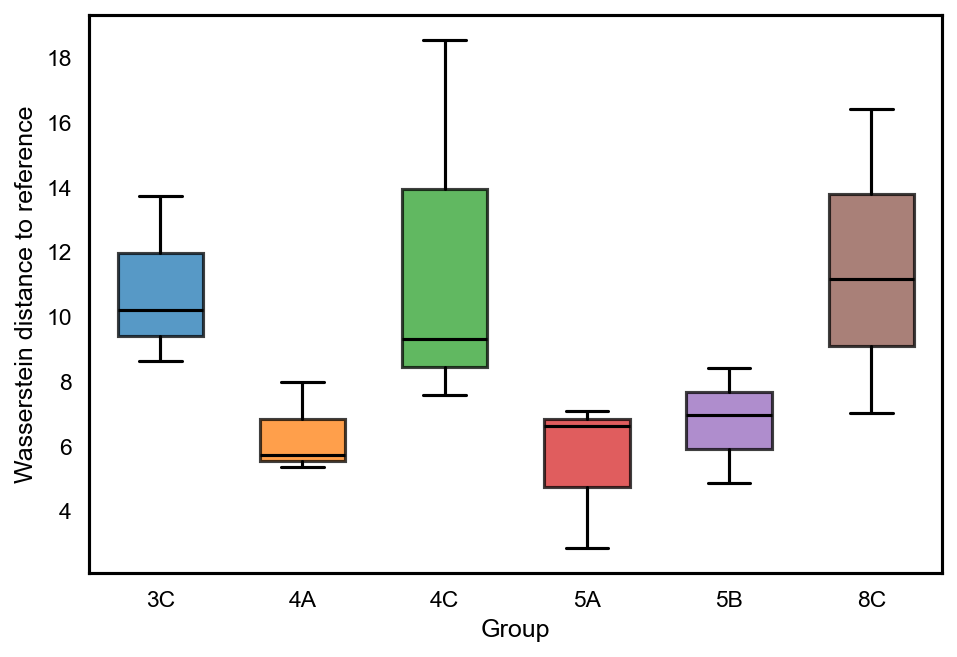

In [97]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6.5, 4.5), dpi=150)

box = ax.boxplot(
    group_distances,
    tick_labels=['3C', '4A', '4C', '5A', '5B', '8C'],
    patch_artist=True,
    widths=0.6,
    showfliers=False
)

# Color boxes
colors = plt.cm.tab10.colors
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.5)

# Style whiskers, caps, medians
for element in ['whiskers', 'caps', 'medians']:
    for line in box[element]:
        line.set_color('black')
        line.set_linewidth(1.5)

# Labels and title
ax.set_ylabel("Wasserstein distance to reference", fontsize=12, color='black')
# ax.set_title("Distribution shape differences across groups", fontsize=13, pad=10)

# Remove gridlines
ax.grid(False)

# Dark axes
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')

ax.tick_params(axis='both', width=1.5, labelsize=11, colors='black')
ax.set_xlabel("Group", fontsize=12, color='black')
ax.set_ylabel("Wasserstein distance to reference", fontsize=12, color='black')
plt.tight_layout()

# Save the image
plt.savefig("Wasserstein_Distance_of_Gravy_Score.jpg", dpi=300, bbox_inches="tight", facecolor="white")

plt.show()


### 9) Empirical Cumulative Distribution Function (ECDFs)

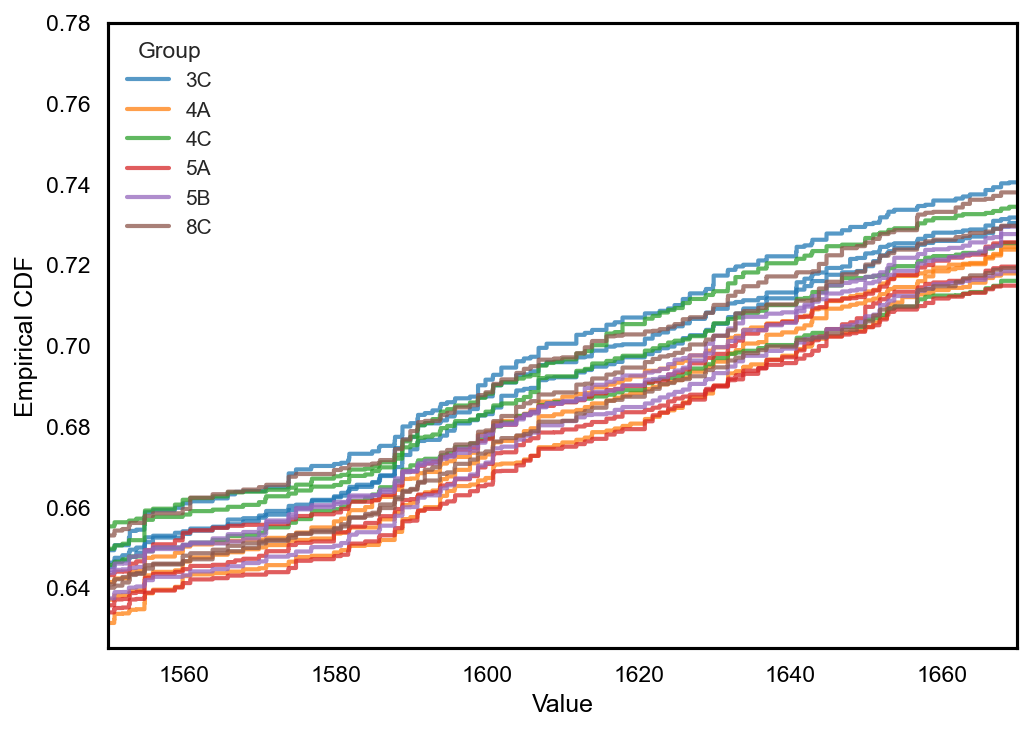

In [98]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(7, 5), dpi=150)

colors = plt.cm.tab10.colors
group_labels = ['3C', '4A', '4C', '5A', '5B', '8C']

for i, group in enumerate(final_nested_lists):
    color = colors[i % len(colors)]

    for j, sample in enumerate(group):
        sample = np.sort(sample)
        y = np.linspace(0, 1, len(sample), endpoint=False)

        ax.step(
            sample,
            y,
            where="post",
            color=color,
            alpha=0.75,
            linewidth=2,
            label=group_labels[i] if j == 0 else None
        )

# Axis labels
ax.set_xlabel("Value", fontsize=12, color="black")
ax.set_ylabel("Empirical CDF", fontsize=12, color="black")
ax.set_ylim(0.625, 0.78)
ax.set_xlim(1550, 1670)

# Remove grid
ax.grid(False)

# Darken axes and ticks
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color("black")

ax.tick_params(
    axis='both',
    which='both',
    width=1.5,
    colors='black',
    labelsize=11
)

# Legend
ax.legend(
    title="Group",
    frameon=False,
    fontsize=10,
    title_fontsize=11
)



plt.tight_layout()


# Save the image
plt.savefig(
    "ECDF_of_Gravy_Score.jpg",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Example 3: Hela Cell Lysates

In [99]:
import pandas as pd
import numpy as np

## 3A) Heat maps of Hela Cell lysates

In [100]:
# File path for figure
HeLa_SI_matrix = './M03_raw_data_for_figures/Hela_similarity_dataframe.csv'

# Import Similarity Dataframe
HeLa_similarity_matrix = pd.read_csv(HeLa_SI_matrix)
HeLa_similarity_matrix

,sample,A01,A02,A03,A04,A05,A06,A07,A08,A09,...,D12,D13,D14,D15,E01,E02,E03,E04,E05,E06
0,A01,1.000000,0.612500,0.629167,0.641250,0.573333,0.617083,0.685000,0.612202,0.685000,...,0.492708,0.537500,0.580952,0.491667,0.406250,0.323750,0.410417,0.447083,0.408333,0.460833
1,A02,0.612500,1.000000,0.594203,0.566667,0.501449,0.451691,0.520773,0.567633,0.520773,...,0.419082,0.514493,0.489303,0.425121,0.404348,0.375362,0.451691,0.436232,0.449275,0.452174
2,A03,0.629167,0.594203,1.000000,0.590498,0.555656,0.557014,0.610860,0.593083,0.610860,...,0.419683,0.493213,0.491273,0.506787,0.317195,0.376018,0.485520,0.507240,0.483258,0.492308
3,A04,0.641250,0.566667,0.590498,1.000000,0.663415,0.709978,0.761863,0.805005,0.761863,...,0.610865,0.727716,0.669876,0.616851,0.494457,0.462528,0.513082,0.542350,0.501109,0.556984
4,A05,0.573333,0.501449,0.555656,0.663415,1.000000,0.590909,0.721977,0.711575,0.721977,...,0.534643,0.586496,0.683016,0.607458,0.495587,0.567079,0.535305,0.593557,0.552515,0.578994
5,A06,0.617083,0.451691,0.557014,0.709978,0.590909,1.000000,0.622203,0.638187,0.622203,...,0.460070,0.619131,0.632358,0.605748,0.481351,0.386573,0.602457,0.689337,0.648530,0.674857
6,A07,0.685000,0.520773,0.610860,0.761863,0.721977,0.622203,1.000000,0.790091,1.000000,...,0.618085,0.662128,0.689605,0.678936,0.454894,0.485532,0.452340,0.480426,0.440851,0.494468
7,A08,0.612202,0.567633,0.593083,0.805005,0.711575,0.638187,0.790091,1.000000,0.771097,...,0.554027,0.761021,0.700696,0.608717,0.464236,0.468611,0.493271,0.523898,0.480742,0.539211
8,A09,0.685000,0.520773,0.610860,0.761863,0.721977,0.622203,1.000000,0.771097,1.000000,...,0.618085,0.662128,0.689605,0.678936,0.454894,0.485532,0.452340,0.480426,0.440851,0.494468
9,B01,0.420833,0.427536,0.455882,0.419956,0.364519,0.420799,0.394255,0.469009,0.394255,...,0.210710,0.436554,0.395809,0.287544,0.172992,0.122002,0.386729,0.386729,0.404889,0.421653


In [101]:
# Data Wrangling

# Strip any leading/trailing spaces that might remain.  (There shouldn't be any.)
HeLa_similarity_matrix.columns = HeLa_similarity_matrix.columns.str.strip()

# Make the sample column the index
HeLa_similarity_matrix = HeLa_similarity_matrix.set_index('sample')

# Replace elements below the main diagonal with NaN
HeLa_similarity_matrix = HeLa_similarity_matrix.where(np.triu(np.ones(HeLa_similarity_matrix.shape, dtype=bool)))


# Reverse order of all columns
# similarity_matrix = similarity_matrix.iloc[:, ::-1]

HeLa_similarity_matrix

,A01,A02,A03,A04,A05,A06,A07,A08,A09,B01,...,D12,D13,D14,D15,E01,E02,E03,E04,E05,E06
sample,,,,,,,,,,,,,,,,,,,,,
A01,1.000000,0.612500,0.629167,0.641250,0.573333,0.617083,0.685000,0.612202,0.685000,0.420833,...,0.492708,0.537500,0.580952,0.491667,0.406250,0.323750,0.410417,0.447083,0.408333,0.460833
A02,NaN,1.000000,0.594203,0.566667,0.501449,0.451691,0.520773,0.567633,0.520773,0.427536,...,0.419082,0.514493,0.489303,0.425121,0.404348,0.375362,0.451691,0.436232,0.449275,0.452174
A03,NaN,NaN,1.000000,0.590498,0.555656,0.557014,0.610860,0.593083,0.610860,0.455882,...,0.419683,0.493213,0.491273,0.506787,0.317195,0.376018,0.485520,0.507240,0.483258,0.492308
A04,NaN,NaN,NaN,1.000000,0.663415,0.709978,0.761863,0.805005,0.761863,0.419956,...,0.610865,0.727716,0.669876,0.616851,0.494457,0.462528,0.513082,0.542350,0.501109,0.556984
A05,NaN,NaN,NaN,NaN,1.000000,0.590909,0.721977,0.711575,0.721977,0.364519,...,0.534643,0.586496,0.683016,0.607458,0.495587,0.567079,0.535305,0.593557,0.552515,0.578994
A06,NaN,NaN,NaN,NaN,NaN,1.000000,0.622203,0.638187,0.622203,0.420799,...,0.460070,0.619131,0.632358,0.605748,0.481351,0.386573,0.602457,0.689337,0.648530,0.674857
A07,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.790091,1.000000,0.394255,...,0.618085,0.662128,0.689605,0.678936,0.454894,0.485532,0.452340,0.480426,0.440851,0.494468
A08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.771097,0.469009,...,0.554027,0.761021,0.700696,0.608717,0.464236,0.468611,0.493271,0.523898,0.480742,0.539211
A09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.394255,...,0.618085,0.662128,0.689605,0.678936,0.454894,0.485532,0.452340,0.480426,0.440851,0.494468


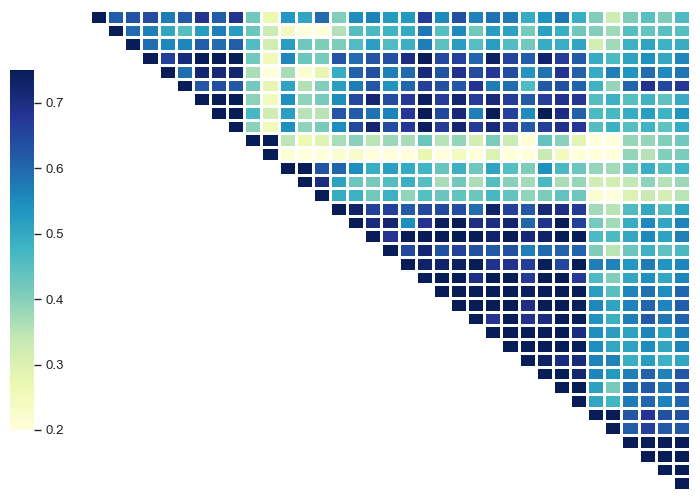

In [102]:
import matplotlib.pyplot as plt
import seaborn as sns

fig = plt.figure(figsize=(8, 6))

# Create axes: [left, bottom, width, height]
cbar_ax = fig.add_axes([0.05, 0.2, 0.03, 0.6])   # left side colorbar
ax = fig.add_axes([0.15, 0.1, 0.75, 0.8])        # main heatmap

sns.heatmap(
    HeLa_similarity_matrix,
    cmap="YlGnBu",
    vmin=0.20,
    vmax=0.75, 
    linewidths=1.0,
    cbar=True,
    cbar_ax=cbar_ax,
    ax=ax
)

# Move the y-axis ticks and labels to the right
ax.yaxis.tick_right() #
# Rotate y-tick labels by 90 degrees
ax.tick_params(axis='y', labelrotation= 0)

# Remove labels on both Axis
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")


# Saves the image as a .jpg file
plt.savefig('Heatmap_of_HeLa.jpg')

plt.show()


## 3B) PSM Figure

In [103]:
# File path for figure
HeLa_summary_info_path = './M03_raw_data_for_figures/HeLa_summary_info.csv'

# Import Similarity Dataframe
HeLa_summary_info = pd.read_csv(HeLa_summary_info_path).T
HeLa_summary_info.columns = HeLa_summary_info.iloc[0]
HeLa_summary_info = HeLa_summary_info[1:].reset_index(drop=True)
HeLa_summary_info

Unnamed: 0,Protein Groups,Peptides,PSM
0,3387,17481,21824
1,3418,17281,21690
2,3738,19559,24479
3,4525,29963,40920
4,4119,27057,35972
5,5354,33592,47915
6,5389,36458,51374
7,5353,36207,52361
8,5389,36458,51374
9,1558,6709,17563


In [104]:
HeLa_summary_info['group'] = ['A1', 'A1', 'A1', 'A2', 'A2', 'A2', 'A3', 'A3', 'A3',
                              'B1', 'B1',
                              'C1', 'C1', 'C1',
                              'D1', 'D1', 'D1', 'D2', 'D2', 'D2',  'D3', 'D3', 'D3', 'D4', 'D4', 'D4', 'D5', 'D5', 'D5', 
                              'E1', 'E1', 'E2', 'E2', 'E3', 'E3']
HeLa_summary_info

                            

Unnamed: 0,Protein Groups,Peptides,PSM,group
0,3387,17481,21824,A1
1,3418,17281,21690,A1
2,3738,19559,24479,A1
3,4525,29963,40920,A2
4,4119,27057,35972,A2
5,5354,33592,47915,A2
6,5389,36458,51374,A3
7,5353,36207,52361,A3
8,5389,36458,51374,A3
9,1558,6709,17563,B1


In [105]:
HeLa_PSM_results = HeLa_summary_info.groupby('group')['PSM'].agg(['mean', 'std'])

# Optional: Rename the columns for clarity (e.g., to 'mean_A' and 'std_A')
HeLa_PSM_results.columns = ['mean', 'std']

# Optional: Reset the index to turn the 'B' group labels into a regular column
HeLa_PSM_results = HeLa_PSM_results.reset_index()

print(HeLa_PSM_results)

   group         mean         std
0     A1 22664.333333 1572.974995
1     A2 41602.333333 6000.666324
2     A3 51703.000000  569.844716
3     B1 17198.500000  515.480843
4     C1 22568.666667  522.234941
5     D1 47819.666667 4724.875695
6     D2 45992.333333 5005.828836
7     D3 42965.333333  279.315831
8     D4 40593.333333 1372.082481
9     D5 46119.000000  886.448532
10    E1 34739.000000 1689.985207
11    E2 45821.500000  226.981277
12    E3 45551.500000  125.157900


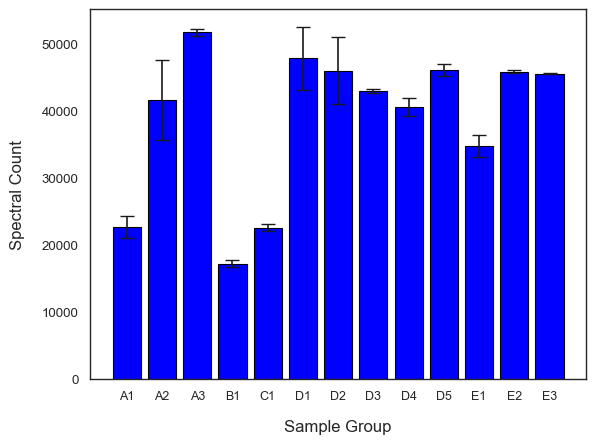

In [106]:


# Create the bar chart
plt.bar(HeLa_PSM_results['group'], HeLa_PSM_results['mean'], 
        yerr=HeLa_PSM_results['std'], capsize=5, color='blue', edgecolor='black')

plt.xticks(fontsize=9)
# Add labels and title
plt.xlabel('Sample Group', fontsize=12, labelpad=12)
plt.ylabel('Spectral Count', fontsize=12, labelpad=12)

# Save the Figure as a jpg file
plt.savefig('HeLa_PSMs_per_group_fig.jpg', dpi=300, bbox_inches='tight')


# Display the plot
plt.show()





## 3C) HeLa Similarity Index Bar chart

In [107]:
HeLa_vs_first_run = HeLa_similarity_matrix.head(1).T
HeLa_vs_first_run['group'] = ['A1', 'A1', 'A1', 'A2', 'A2', 'A2', 'A3', 'A3', 'A3',
                              'B1', 'B1',
                              'C1', 'C1', 'C1',
                              'D1', 'D1', 'D1', 'D2', 'D2', 'D2',  'D3', 'D3', 'D3', 'D4', 'D4', 'D4', 'D5', 'D5', 'D5', 
                              'E1', 'E1', 'E2', 'E2', 'E3', 'E3']
# Drop first row.  (It should be 1.00)
HeLa_vs_first_run = HeLa_vs_first_run.drop(HeLa_vs_first_run.columns[0], axis=0)

HeLa_similarity_stats = HeLa_vs_first_run.groupby('group')['A01'].agg(['mean', 'std'])

HeLa_similarity_stats = HeLa_similarity_stats.reset_index()
print(HeLa_similarity_stats)




   group     mean      std
0     A1 0.620833 0.011785
1     A2 0.610556 0.034426
2     A3 0.660734 0.042030
3     B1 0.346615 0.104961
4     C1 0.544306 0.044340
5     D1 0.505565 0.086956
6     D2 0.573472 0.080741
7     D3 0.582778 0.044116
8     D4 0.550645 0.050386
9     D5 0.536706 0.044648
10    E1 0.365000 0.058336
11    E2 0.428750 0.025927
12    E3 0.434583 0.037123


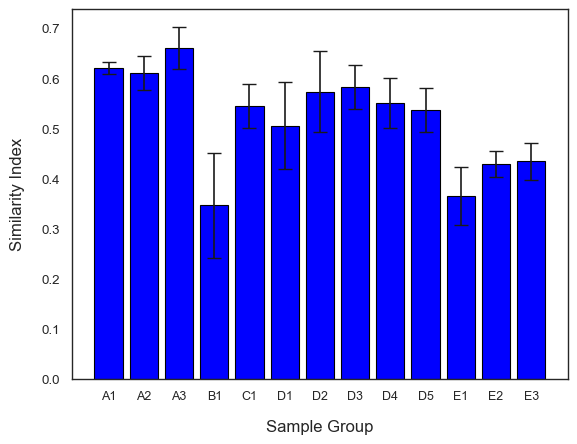

In [108]:


# Create the bar chart
plt.bar(HeLa_similarity_stats['group'], HeLa_similarity_stats['mean'], 
        yerr=HeLa_similarity_stats['std'], capsize=5, color='blue', edgecolor='black')

plt.xticks(fontsize=9)
# Add labels and title
plt.xlabel('Sample Group', fontsize=12, labelpad=12)
plt.ylabel('Similarity Index', fontsize=12, labelpad=12)

# Save the Figure as a jpg file
plt.savefig('HeLa_SI_per_group_fig.jpg', dpi=300, bbox_inches='tight')


# Display the plot
plt.show()
